# M2 questions and replies: check notebook

## Plain-language guide

**Why the study needs this module.** The paper asks whether a newcomer who gets a reply from a mentor keeps editing
Wikipedia more often than a similar newcomer who gets no reply. To answer that, we must know, for every question a
newcomer sent to a mentor: when it was asked, who asked it, which mentor it went to, whether anyone answered, who
answered, and when. M2 builds exactly that table. Its "reply or not" column is the **treatment** of the study (the thing
whose effect we measure), and the first reply time is the moment from which later activity is counted. The question
text is also passed on to M6, which measures things like politeness and topic.

**What raw data it collects, and from where.** All data come from the public English Wikipedia API
(`en.wikipedia.org/w/api.php`); nothing is private.

* The list of questions: every edit on a mentor's user talk page that Wikipedia tagged `mentorship module question` or
  `mentorship panel question` (the tags the "ask your mentor" button adds). Most of the list comes from an earlier
  collection of this project (called **eval2**, 44,650 records, downloaded 2026-06-12); a new "top-up" sweep over the
  mentors' talk pages added 16 more, of which 8 fall before the cutoff.
* The talk pages and their archives (9,884 pages) as they stood at the cutoff, parsed by Wikipedia's own
  **DiscussionTools** service (`action=discussiontoolspageinfo`), which splits a talk page into threads and signed comments.
* For threads that were deleted or moved away before the cutoff: older revisions of the page (`action=parse` on one section).
* The page move log (212 moves), so a talk page renamed later can be traced back to its name at question time.
* The edit right after each question, to see whether the question was removed at once and why.
* User ids for signature names that are not on the mentor roster (887 of 1,274 names resolved).

Only questions saved before the **cutoff, 2026-04-20T14:00:00Z**, are kept, and only replies before the cutoff count.
The download scripts used a slightly later window (to 2026-04-24) to be safe; the build step then cuts at 2026-04-20T14:00Z.

**What it does, step by step.**

1. Build the list of questions (one per tagged edit before the cutoff).
2. Find the talk page title at the time of the question (pages are sometimes renamed later) and the mentor who owns it.
3. Read the "your mentor is away" note, if any, to learn the newcomer's own (primary) mentor, and remove the note from the text.
4. Find the thread that holds the question in the DiscussionTools parse (or in old revisions if it was deleted).
5. Split the thread into **turns** (one signed comment each) and label each speaker: the newcomer, the page's mentor,
   the away (primary) mentor, another mentor, someone else, or unknown.
6. Compute the reply fields: was there any reply, the first reply time and replier, was there a mentor reply, and counts of turns.
7. Clean the question text (remove templates, signatures and markup) and flag unusual cases for later modules.

**What it produces.**

* `data/interim/m2/questions.parquet`: **one row = one question** (42,316 rows in this run). Key columns: the question's
  revision id, time, asker, talk page and its mentor, primary mentor, whether the question was asked from the article
  editor, the question text, whether a thread was found, `has_any_reply` (the treatment), first reply time and replier
  and their role, `has_mentor_reply`, turn counts, and a list of problem flags.
* `data/interim/m2/turns.jsonl`: **one row = one question**, holding the list of its turns (91,906 turns in total). Each turn
  has the signer's name and user id, the role, the time (to the minute), the reply depth, the text and link counts.
* `data/interim/m2/_issues/*.jsonl`: one file per kind of unusual case, one line per affected question, so each can be looked up.
* `results/m2_report.json`: a short summary (counts and rates) read by the final report.

## How to read this notebook

* All outputs below are already saved from the run on the final data (cutoff 2026-04-20T14:00Z). You do not need to run anything.
* Each automatic check prints `[OK ]` (the rule holds for every row) or `[FAIL]` (it does not). In this run every check printed `[OK ]`.
* An **invariant** is a rule that must always be true, for example "no question is after the cutoff".
* **Recomputed vs stored**: the notebook re-derives a value with its own short code (not the pipeline's code) and compares
  it with the value the pipeline saved. A match means two independent implementations agree.
* A **tracer** is a fixed question chosen in advance because it is a known tricky case; the same tracers are followed
  through every module. A **random sample** is a set of questions drawn by chance (fixed seed, so it is repeatable)
  to show typical cases in full.
* Links of the form `en.wikipedia.org/w/index.php?oldid=...` open the exact edit on Wikipedia, so anyone can check by eye.

## 1. What this module does (technical summary)

**Code**: `pipeline/m2_conversations/` (`collect_topup.py` downloads raw data, `turns.py` splits a thread into turns,
`build_questions.py` builds the tables offline).
**Rules**: DATA_PROCESSING R4.1 to R4.6 (questions), R5.1 to R5.6 (replies), R6.1 and R6.2 (names and uids); issues I-34, I-45, I-55.

When a newcomer clicks "ask your mentor", Wikipedia saves a new section on the mentor's talk page and tags
that revision `mentorship module question` or `mentorship panel question`. M2 does the following:

1. **Questions** (R4.1): one row per tagged revision before the cutoff (2026-04-20T14:00:00Z). The list comes from
   eval2's collection plus a later top-up sweep.
2. **Talk page owner** (I-45): if the talk page was moved later (for example a mentor renamed), the move log is followed
   backwards to get the title at question time (`page_title_at_q`); its owner is `page_mentor_uid`.
3. **Away notice** (R4.2, R4.4): when the newcomer's own mentor is away, the question goes to a backup mentor and starts with
   `Note: X's mentor Y is away.` Y is the **primary mentor**. The note is removed from the text.
4. **Thread and turns** (R5.1, R5.5): the thread holding the question is found in Wikipedia's own DiscussionTools parse of each
   talk page and archive at the cutoff. Sections deleted before the cutoff are recovered from revision history (R5.6).
5. **Speaker role** of each turn (R5.2): `mentee` (the asker), `page_mentor` (owner of the talk page), `primary_mentor`
   (the away mentor), `other_mentor` (another mentor on the roster at that time), `third_party` (anyone else), `unknown`
   (no signature found). The decision uses user ids, M1's mentor names, and an alt-account table.
6. **Reply fields** (R5.3): a reply is any turn not by the newcomer, at or after the question minute and before the cutoff.
   `has_any_reply` is the main treatment; `first_reply_ts` starts the clock; `has_mentor_reply` (page or primary mentor) is the robustness version.

**Paper numbers that depend on it**: the treatment (reply or not), the timing origin (first reply time), reply
features (RQ3), and the question text (M6).

## Technical notes on this notebook

* The saved outputs are from the run on the final data (cutoff 2026-04-20T14:00Z). Rerunning all cells takes a few minutes. Every check prints `[OK ]` or `[FAIL]`;
  mismatch tables print `MISMATCH` (none appear in this run).
* Section 3.2 recomputes every derived field for **all** questions with simple code written here (not the pipeline functions).
* Section 5 shows random questions in full: raw wikitext next to cleaned text, the raw DiscussionTools record next to each
  processed turn, the reason for each speaker role, and a recomputed-versus-stored table. Change `SEED` below to see other questions.

**What this cell does.** It loads the M2 outputs and the raw downloaded files that the checks below compare against.
It is not a check itself; it prints how many records were loaded.

In [1]:
# ── setup ────────────────────────────────────────────────────────────────────
SEED = 0          # change this number to draw a fresh random sample in sections 3.3 and 5
N_RANDOM = 5      # how many random questions to show in each group
N_BULK = 1000     # how many random questions get the bulk "raw DiscussionTools vs turns" check in 3.3

import json, re, sys, html as _html
from collections import defaultdict, Counter
from pathlib import Path
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import config
from pipeline.common.io import read_jsonl, iter_jsonl
from pipeline.common.tracer import tracer_frame
from checks._show import Checks, compare, pick, oldid, diff, contribs, logid
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 220)
M2 = config.INTERIM / "m2"; RAW = config.RAW / "m2"; CUTOFF = config.DATA_CUTOFF_ISO
q = pd.read_parquet(M2 / "questions.parquet")
qi = q.set_index("question_revid", drop=False)
turns = {r["question_revid"]: r["turns"] for r in iter_jsonl(M2 / "turns.jsonl")}
pages = {p["title"]: p for p in iter_jsonl(RAW / "pages.jsonl")}
moves = read_jsonl(RAW / "move_log.jsonl")
fb_map = json.loads((RAW / "fallback_map.json").read_text())
removals = json.loads((RAW / "removal_edits.json").read_text())
resolved_raw = json.loads((RAW / "replier_uids.json").read_text())   # signature name -> uid, looked up online in the fallback phase
topup = {int(r["revid"]): r for r in iter_jsonl(RAW / "tag_topup.jsonl")}
topup_wt = json.loads((RAW / "question_wikitext.json").read_text())
EV_KEEP = ("revid", "timestamp", "parentid", "page", "mentor_uid", "mentee_uid", "mentee", "heading", "question_text",
           "tags", "has_any_reply", "first_reply_ts", "first_replier_name")
ev = {int(r["revid"]): {k: r.get(k) for k in EV_KEEP} for r in iter_jsonl(config.EXTERNAL["eval2_conversations"])}
print(f"questions {len(q)} | with turns {len(turns)} | pages {len(pages)} | eval2 records {len(ev)} | top-up {len(topup)}")

questions 42316 | with turns 42316 | pages 9884 | eval2 records 44650 | top-up 16


**What the output shows.** In the run on the final data (cutoff 2026-04-20T14:00Z): 42,316 questions, each with a turns record; 9,884 talk pages; 44,650 eval2
records and 16 top-up records. eval2 has more records than the table because its download (2026-06-12) also contains
questions saved after the cutoff, which are left out on purpose.

## 2. Files and manifest

**What this checks.** Each step writes a small "manifest" file saying when it finished, which cutoff it used, and how many
items it handled. This shows the files come from the expected run.

In [2]:
for name in ("m2_collect_pages", "m2_collect_fallback", "m2"):
    p = config.INTERIM / name / "manifest.json"
    if not p.exists():
        print(name, ": no manifest"); continue
    man = json.loads(p.read_text())
    print(f"\n[{name}] finished {man['finished_at']} | cutoff {man['data_cutoff']} | {man['elapsed_sec']} s")
    print(json.dumps(man["counts"], ensure_ascii=False, indent=1)[:1500])


[m2_collect_pages] finished 2026-10-07T15:55:41.459666+00:00 | cutoff 2026-04-24T00:00:00Z | 5716.3 s
{
 "pages_skipped_pre_mentorship": 6793,
 "unscanned_mentors": 11,
 "topup_questions": 16,
 "moves": 212,
 "pages": 9884,
 "pages_existing": 9630,
 "api": {
  "cache_hit": 1325,
  "network": 3657,
  "retries": 6
 }
}

[m2_collect_fallback] finished 2026-10-08T01:40:03.163029+00:00 | cutoff 2026-04-24T00:00:00Z | 10791.2 s
{
 "topup_text": 16,
 "fallback_requested": 4303,
 "fallback_recovered": 4246,
 "names_requested": 1274,
 "names_resolved": 887,
 "api": {
  "cache_hit": 9329,
  "network": 7931,
  "retries": 1
 }
}

[m2] finished 2026-10-26T14:04:28.672572+00:00 | cutoff 2026-04-20T14:00:00Z | 170.5 s
{
 "questions": 42316,
 "thread_found": 42220,
 "has_any_reply": 31153,
 "has_mentor_reply": 29742,
 "away_routed": 517,
 "editing_page": 7791,
 "first_replier_role": {
  "page_mentor": 29289,
  "third_party": 1207,
  "other_mentor": 657
 }
}


**What the output shows.** The two download steps (`m2_collect_pages`, `m2_collect_fallback`) list cutoff 2026-04-24: they
downloaded a few extra days on purpose, and the build step (`m2`, finished 2026-10-26) applies the real cutoff
2026-04-20T14:00:00Z. The build reports 42,316 questions, a thread found for 42,220, a reply for 31,153 and a mentor reply
for 29,742. Of 4,303 deleted threads looked for in old revisions, 4,246 were recovered. "unscanned_mentors: 11" means 11
mentors' pages were not swept by the top-up search (the top-up only adds questions eval2 missed, so this can at most miss a few).

### Data dictionary

Every column of `questions.parquet` and every field of a turn in `turns.jsonl`: what it means and where it is checked.
"3.1" = structural invariant, "3.2" = recomputed for all rows, "3.3" = bulk raw-parser comparison, "5.x" = random side-by-side examples.

In [3]:
DD_Q = [
 ("question_revid", "revision id of the tagged question (primary key)", "3.1 unique; 3.2 present in raw eval2 or top-up"),
 ("parentid", "the revision before the question", "3.2 equals raw record"),
 ("q_ts", "time the question was saved", "3.1 before cutoff; 3.2 equals raw record"),
 ("mentee_uid / mentee_name", "user id and normalized name of the asker (revision author)", "3.2 equals raw record; 5.R"),
 ("tag / source", "which Mentorship tag; eval2 or top-up", "3.1 tag in QUESTION_TAGS; 3.2 tag from raw tags; top-up count"),
 ("heading", "section heading, lower case (eval2) or from the edit summary (top-up)", "3.2 equals raw record; 5.R"),
 ("page_eval", "talk page title as recorded by eval2 (title today)", "3.2 equals raw record"),
 ("page_title_at_q", "talk page title at question time, by following the move log backwards", "3.2 recomputed; 5.M page moves"),
 ("page_mentor_uid", "uid of the owner of page_title_at_q (eval2 mentor if the owner is not a known mentor)", "3.2 recomputed; 5.R"),
 ("eval_mentor_uid", "mentor uid recorded by eval2", "3.2 equals raw record; section 6 page_owner_differs"),
 ("away_routed / primary_mentor_name / primary_mentor_uid", "away notice present; mentor named in it (else page mentor)", "3.2 recomputed by own regex; 5.A"),
 ("editing_page / article_context", "asked from the editor (panel tag + 'on <page>' in heading); that page", "3.2 recomputed; 5.E; section 6 differences"),
 ("question_wikitext", "raw question wikitext with the away notice removed", "3.2 equals raw minus note; 5.R side by side"),
 ("question_text", "plain text of the question (templates, signatures, user links removed)", "3.1 source rule; 5.R side by side; section 6 leftover markup"),
 ("question_text_source / question_text_dt", "where question_text came from; first turn text if the first turn is the mentee", "3.1 rules"),
 ("thread_page / thread_revid / thread_origin", "page and revision where the thread was found; cutoff or fallback type", "3.1 cutoff revid == pages.jsonl; 3.3; 5.R raw thread"),
 ("match_score", "points for heading, asker, owner, and recovered-for-this-question", "5.R recomputed from the raw thread key and heading"),
 ("n_turns", "number of turns kept (before the cutoff)", "3.1 == len(turns); 3.2"),
 ("has_any_reply / first_reply_ts / first_replier_name / first_replier_uid / first_replier_role", "reply by anyone but the newcomer, and the first one", "3.2 recomputed for all rows; 5.R"),
 ("has_mentor_reply / mentor_first_reply_ts", "reply by the page mentor or primary mentor, and its time", "3.2; 5.R"),
 ("n_reply_turns / n_mentor_turns / n_third_party_turns / n_mentee_turns", "counts of turns by type", "3.2; 5.R"),
 ("removal_kind", "why the question was deleted in the next edit (revert, self_removed, merged, other)", "3.2 recomputed from raw edit; 5.D"),
 ("eval_has_any_reply", "eval2's reply status (for comparison)", "3.2 equals raw record; section 4"),
 ("parse_flags", "list of problem flags", "3.1 each flag's rule; section 6 lists"),
]
DD_T = [
 ("author", "signature name found by DiscussionTools (normalized)", "3.3 equals raw author; 5.R"),
 ("signer_uid", "uid of the signer (mentee_uid for the newcomer, mentor uid, or looked-up uid)", "3.2 recomputed; 5.R"),
 ("role", "speaker role (see section 1)", "3.2 recomputed for every turn; 5.R shows the reason"),
 ("ts", "turn time to the minute", "3.1 before cutoff; 3.3 equals raw timestamp"),
 ("level", "reply depth", "3.3 equals raw level"),
 ("comment_id", "DiscussionTools comment id", "3.3 equals raw id"),
 ("text", "plain text of the turn", "5.R next to the raw HTML text; 5.F merged questions"),
 ("links", "internal links, number of external links and list items in the turn HTML", "3.3 n_external and n_list_items counted from raw HTML"),
]
print("questions.parquet columns covered:", sorted(set(q.columns) - {c.strip() for row in DD_Q for c in row[0].split("/")}) or "all")
display(pd.DataFrame(DD_Q, columns=["column", "meaning", "checked in"]))
display(pd.DataFrame(DD_T, columns=["turn field", "meaning", "checked in"]))

questions.parquet columns covered: ['question_wikitext_origin']


,column,meaning,checked in
0,question_revid,revision id of the tagged question (primary key),3.1 unique; 3.2 present in raw eval2 or top-up
1,parentid,the revision before the question,3.2 equals raw record
2,q_ts,time the question was saved,3.1 before cutoff; 3.2 equals raw record
3,mentee_uid / mentee_name,user id and normalized name of the asker (revision author),3.2 equals raw record; 5.R
4,tag / source,which Mentorship tag; eval2 or top-up,3.1 tag in QUESTION_TAGS; 3.2 tag from raw tags; top-up count
5,heading,"section heading, lower case (eval2) or from the edit summary (top-up)",3.2 equals raw record; 5.R
6,page_eval,talk page title as recorded by eval2 (title today),3.2 equals raw record
7,page_title_at_q,"talk page title at question time, by following the move log backwards",3.2 recomputed; 5.M page moves
8,page_mentor_uid,uid of the owner of page_title_at_q (eval2 mentor if the owner is not a known mentor),3.2 recomputed; 5.R
9,eval_mentor_uid,mentor uid recorded by eval2,3.2 equals raw record; section 6 page_owner_differs


,turn field,meaning,checked in
0,author,signature name found by DiscussionTools (normalized),3.3 equals raw author; 5.R
1,signer_uid,"uid of the signer (mentee_uid for the newcomer, mentor uid, or looked-up uid)",3.2 recomputed; 5.R
2,role,speaker role (see section 1),3.2 recomputed for every turn; 5.R shows the reason
3,ts,turn time to the minute,3.1 before cutoff; 3.3 equals raw timestamp
4,level,reply depth,3.3 equals raw level
5,comment_id,DiscussionTools comment id,3.3 equals raw id
6,text,plain text of the turn,5.R next to the raw HTML text; 5.F merged questions
7,links,"internal links, number of external links and list items in the turn HTML",3.3 n_external and n_list_items counted from raw HTML


**What the output shows.** Two tables explaining every column and where it is checked. The first line reports one column
not described in the table: `question_wikitext_origin`. It says where the question text came from: `collected` (the text
from eval2 or the top-up, 42,164 questions) or `diff` (152 questions whose collected text was obviously broken, for example
folded away by a later template, so the text was taken again from the edit that posted the question; see PLAN.md issue I-60).
Section 3.2 uses that same diff text when it recomputes the question text, so this column is covered in practice.

## 3. Invariants

### 3.1 Structure and flag rules

**What this checks.** Basic rules that must hold for every row: each question appears once, nothing is after the cutoff,
a reply is never earlier than the question, a mentor reply always counts as a reply, and each problem flag is set exactly
when its condition is true. If any of these failed, the treatment or the timing in the paper could be wrong.

In [4]:
ck = Checks()
qts = pd.to_datetime(q.q_ts, utc=True)
qmin = q.q_ts.str[:17] + "00Z"                      # question time rounded down to the minute
all_turn_ts = [t["ts"] for ts in turns.values() for t in ts if t["ts"]]
found = q.thread_page.notna()
ck.add("primary key question_revid is unique", q.question_revid.is_unique)
ck.add("every question has a turns row and vice versa", set(turns) == set(q.question_revid))
ck.add("no question at or after the cutoff", (qts < config.DATA_CUTOFF).all())
ck.add("no turn at or after the cutoff", all(t < CUTOFF for t in all_turn_ts))
ck.add("first reply is not earlier than the question minute",
       (q.first_reply_ts.dropna() >= qmin[q.first_reply_ts.notna()]).all())
ck.add("mentor reply implies any reply", (~q.has_mentor_reply.fillna(False).astype(bool) | q.has_any_reply.fillna(False).astype(bool)).all())
ck.add("every tag is one of the two Mentorship tags", q.tag.isin(config.QUESTION_TAGS).all())
ck.add("all top-up questions before the cutoff are in the table",
       set(q[q.source == "topup"].question_revid) == {r for r, x in topup.items() if x["timestamp"] < CUTOFF})
ck.add("n_turns == number of turns in turns.jsonl", (q.n_turns == q.question_revid.map(lambda r: len(turns[r]))).all())
ck.add("thread not found <=> thread_page empty <=> flag thread_not_found",
       ((~found) == q.parse_flags.map(lambda f: "thread_not_found" in list(f))).all())
ck.add("thread not found -> reply fields empty and no turns",
       q[~found].has_any_reply.isna().all() and (q[~found].n_turns == 0).all())
ck.add("thread_origin cutoff -> thread_revid is the page revision at the cutoff (pages.jsonl)",
       q[q.thread_origin == "cutoff"].apply(lambda r: pages.get(r.thread_page, {}).get("as_of_revid") == r.thread_revid, axis=1).all())
sec_files = defaultdict(set)      # revision id of a recovered section -> questions it was recovered for
for pth in (RAW / "fallback_sections").glob("*.json"):
    sec_files[int(json.loads(pth.read_text())["revid"])].add(int(pth.stem))
fs = q[q.thread_origin == "fallback_section"]
own = fs.apply(lambda r: r.question_revid in sec_files.get(int(r.thread_revid), set()), axis=1)
ck.add("thread_origin fallback_section -> a recovered section file with this thread_revid exists",
       fs.thread_revid.map(lambda x: int(x) in sec_files).all())
print(f"   recovered for this same question: {int(own.sum())}; recovered for another question in the same revision: "
      f"{int((~own).sum())} {fs[~own].question_revid.tolist()[:10]}")
ck.add("flag turn_source_regex <=> thread_origin fallback_regex",
       (q.parse_flags.map(lambda f: "turn_source_regex" in list(f)) == (q.thread_origin == "fallback_regex")).all())
ft = q.question_revid.map(lambda r: turns[r][0]["role"] if turns[r] else None)
ck.add("flag first_turn_not_mentee <=> first turn exists and is not the mentee",
       (q.parse_flags.map(lambda f: "first_turn_not_mentee" in list(f)) == (ft.notna() & (ft != "mentee"))).all())
rbq = pd.Series([any(t["role"] != "mentee" and t["ts"] and t["ts"] < m for t in turns[r]) for r, m in zip(q.question_revid, qmin)], index=q.index)
ck.add("flag reply_before_question <=> some non-mentee turn is earlier than the question minute",
       (q.parse_flags.map(lambda f: "reply_before_question" in list(f)) == rbq).all())
ck.add("question_text_dt == first turn text when the first turn is the mentee, else empty",
       all((turns[r][0]["text"] if turns[r] and turns[r][0]["role"] == "mentee" else None) == d
           for r, d in zip(q.question_revid, q.question_text_dt)))
ck.add("question_text_source rule: wikitext if wikitext gives text, else discussiontools, else none",
       ((q.question_text_source == "none") == (q.question_text == "")).all()
       and (q[q.question_text_source == "discussiontools"].question_text == q[q.question_text_source == "discussiontools"].question_text_dt).all())
ck.add("removal_kind is set exactly when flag section_removed_immediately is set",
       (q.removal_kind.notna() == q.parse_flags.map(lambda f: "section_removed_immediately" in list(f))).all())
ck.add("no away notice -> primary_mentor_uid == page_mentor_uid and primary_mentor_name empty",
       (q[~q.away_routed].primary_mentor_uid == q[~q.away_routed].page_mentor_uid).all() and q[~q.away_routed].primary_mentor_name.isna().all())
print("\nshare of questions with a thread:", f"{found.mean():.2%}", "| origin:", q.thread_origin.value_counts(dropna=False).to_dict())

  [OK ] primary key question_revid is unique
  [OK ] every question has a turns row and vice versa
  [OK ] no question at or after the cutoff
  [OK ] no turn at or after the cutoff
  [OK ] first reply is not earlier than the question minute
  [OK ] mentor reply implies any reply
  [OK ] every tag is one of the two Mentorship tags
  [OK ] all top-up questions before the cutoff are in the table


/var/folders/nc/j9_n57h95kd01m8qr0xksst00000gn/T/ipykernel_20119/2162657284.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ck.add("mentor reply implies any reply", (~q.has_mentor_reply.fillna(False).astype(bool) | q.has_any_reply.fillna(False).astype(bool)).all())
/var/folders/nc/j9_n57h95kd01m8qr0xksst00000gn/T/ipykernel_20119/2162657284.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ck.add("mentor reply implies any reply", (~q.has_mentor_reply.fillna(False).astype(bool) | q.has_any_reply.fillna(False).astype(bool)).all())


  [OK ] n_turns == number of turns in turns.jsonl
  [OK ] thread not found <=> thread_page empty <=> flag thread_not_found
  [OK ] thread not found -> reply fields empty and no turns


  [OK ] thread_origin cutoff -> thread_revid is the page revision at the cutoff (pages.jsonl)


  [OK ] thread_origin fallback_section -> a recovered section file with this thread_revid exists
   recovered for this same question: 2918; recovered for another question in the same revision: 2 [1218181276, 1248251784]
  [OK ] flag turn_source_regex <=> thread_origin fallback_regex


  [OK ] flag first_turn_not_mentee <=> first turn exists and is not the mentee


  [OK ] flag reply_before_question <=> some non-mentee turn is earlier than the question minute
  [OK ] question_text_dt == first turn text when the first turn is the mentee, else empty
  [OK ] question_text_source rule: wikitext if wikitext gives text, else discussiontools, else none


  [OK ] removal_kind is set exactly when flag section_removed_immediately is set
  [OK ] no away notice -> primary_mentor_uid == page_mentor_uid and primary_mentor_name empty

share of questions with a thread: 99.77% | origin: {'cutoff': 37974, 'fallback_section': 2920, 'fallback': 1325, None: 96, 'fallback_regex': 1}


**What the output shows.** All rules pass (`[OK ]`). The "FutureWarning" lines are a harmless notice from the pandas library
about a future version, not an error. A thread was found for 99.77% of questions: 37,974 from the talk page at the cutoff,
2,920 and 1,325 recovered from older revisions (the thread was deleted or archived elsewhere before the cutoff), 1 split by
a simple signature search, and 96 not found at all (these get no reply value and are left out of the analysis). Two
recovered sections were fetched for a different question in the same revision; that is fine, since one old revision can hold
both questions.

### 3.2 Independent recomputation for every question

The code below re-implements the rules in plain Python, without calling any M2 function:

* **names**: HTML entities decoded, underscores to spaces, first letter upper case, `/subpage` removed, alt accounts mapped to the main account;
* **mentor uid of a name**: from M1's `mentor_names` table (a name that maps to two uids is not used);
* **newcomer names**: the revision author, the asker in the heading, the newcomer named in the away notice, and every
  signature name the fallback phase looked up to the same uid; for flag `question_turn_relabelled`, also the signature of the first turn;
* **role** order: no author -> unknown; newcomer name or uid -> mentee; uid == page mentor -> page_mentor; uid == primary mentor
  -> primary_mentor; a mentor name on the M1 roster at the turn time -> other_mentor; else third_party;
* **reply**: a turn whose role is not mentee, with a time at or after the question minute and before the cutoff.

**What this checks, in plain words.** The next two cells write the module's rules again from scratch, in short and simple
code, and apply them to all 42,316 questions and every turn. Then every stored value is compared with the recomputed one.
This matters because the treatment (`has_any_reply`), the clock start (`first_reply_ts`) and the replier role all feed
directly into the paper's estimates. The first cell only defines helper functions and prints nothing.

In [5]:
def my_name(n):
    if n is None: return None
    n = _html.unescape(str(n)).replace("_", " ")
    n = re.sub(r"[​-‏‪-‮⁠-⁤﻿]", "", n)
    n = re.sub(r"[\s  ]+", " ", n).strip()
    return (n[:1].upper() + n[1:]) or None
ALT = {my_name(a): my_name(m) for a, m in config.MENTOR_ALT_ACCOUNTS.items()}
def person(author):
    """signature name -> the person: drop /subpage, normalize, map alt account to main account"""
    if not author: return None
    p = my_name(str(author).split("/")[0]); return ALT.get(p, p)
mnames = pd.read_parquet(config.INTERIM / "m1" / "mentor_names.parquet")
n2u = defaultdict(set)
for r in mnames.itertuples(): n2u[r.name].add(int(r.mentor_uid))
for a, m in ALT.items(): n2u[a] |= n2u.get(m, set())
MENTOR = {n: next(iter(u)) for n, u in n2u.items() if len(u) == 1}
spans = defaultdict(list)
for r in pd.read_parquet(config.INTERIM / "m1" / "mentor_periods.parquet").itertuples(): spans[r.mentor_uid].append((r.start, r.end))
def on_roster(uid, ts): return any(s <= ts and (e is None or ts < e) for s, e in spans.get(uid, []))
RESOLVED = {my_name(k): v for k, v in resolved_raw.items() if v}

AWAY_RE = re.compile(r"Note:\s*\[\[\s*User(?:[ _]talk)?\s*:\s*([^|\]]+)[^\]]*\]\]\s*'s\s+mentor\s+(?:\[\[\s*User(?:[ _]talk)?\s*:\s*([^|\]]+)[^\]]*\]\]"
                     r"|(?:<span[^>]*>)?\s*\[\S+\s+([^\]]+)\]\s*(?:</span>)?)\s+is\s+away", re.I)
HEAD_ASKER = re.compile(r"^question from (.+?)(?: on .+)? \(\d{1,2}:\d{2}, ")
HEAD_PAGE = re.compile(r"^question from .+? on (.+) \(\d{1,2}:\d{2}, ")
def nhead(h): return re.sub(r"\s+", " ", (h or "").replace("_", " ")).strip().lower()
_dp = RAW / "question_text_from_diff.json"
FROM_DIFF = json.loads(_dp.read_text()) if _dp.exists() else {}     # I-60: text as posted, for the obviously broken questions
def raw_wikitext(rv):
    """the question wikitext as downloaded: the diff of the tagged revision when M2 fetched it (I-60), otherwise the
    eval2 record, or question_wikitext.json for top-up questions"""
    d = (FROM_DIFF.get(str(rv)) or {}).get("text") or ""
    if d.strip(): return d
    return (ev[rv]["question_text"] if rv in ev else (topup_wt.get(str(rv)) or {}).get("text")) or ""
def my_away(rv):
    m = AWAY_RE.search(raw_wikitext(rv)[:1000])
    return None if not m else {"mentee": my_name(m.group(1)), "primary": my_name(m.group(2) or m.group(3)), "match": m.group(0)}

def mentee_names(r):
    """{lower-case name: why it counts as the newcomer}"""
    out = {}
    if r.mentee_name: out[r.mentee_name.lower()] = "revision author (mentee_name)"
    h = HEAD_ASKER.match(nhead(r.heading))
    if h: out.setdefault(h.group(1), "asker in the heading")
    a = my_away(r.question_revid)
    if a and a["mentee"]: out.setdefault(a["mentee"].lower(), "newcomer named in the away notice")
    for n, u in RESOLVED.items():
        if pd.notna(r.mentee_uid) and u == r.mentee_uid: out.setdefault(n.lower(), f"looked up online: uid {u} == mentee_uid")
    ts = turns[r.question_revid]
    if "question_turn_relabelled" in list(r.parse_flags) and ts and ts[0]["author"]:
        out.setdefault(person(ts[0]["author"]).lower(), "signature of the question turn itself (I-55)")
    return out

def my_role(t, i, r, mn):
    """(role, signer uid, reason) for turn number i of question row r"""
    p = person(t["author"])
    if p is None: return "unknown", None, "DiscussionTools found no signature"
    uid = MENTOR.get(p) or RESOLVED.get(p)
    mu = None if pd.isna(r.mentee_uid) else int(r.mentee_uid)
    if i == 0 and "question_turn_relabelled" in list(r.parse_flags):
        return "mentee", mu, "first turn is the question itself (flag question_turn_relabelled)"
    if p.lower() in mn: return "mentee", mu, f"{p!r} is a newcomer name: {mn[p.lower()]}"
    if uid is not None and uid == mu: return "mentee", mu, f"{p!r} -> uid {uid} == mentee_uid"
    if uid is not None and uid == r.page_mentor_uid: return "page_mentor", uid, f"{p!r} -> uid {uid} == page_mentor_uid (owner of {r.page_title_at_q})"
    if uid is not None and uid == r.primary_mentor_uid: return "primary_mentor", uid, f"{p!r} -> uid {uid} == primary_mentor_uid (away notice)"
    if p in MENTOR and on_roster(uid, t["ts"] or ""): return "other_mentor", uid, f"{p!r} is mentor uid {uid}, on the roster at {t['ts']}, not this question's mentor"
    return "third_party", uid, f"{p!r} (uid {uid}) is not the newcomer and not a mentor on the roster at that time"

def my_reply_fields(ts, q_ts):
    qm = q_ts[:17] + "00Z"
    rep = [t for t in ts if t["role"] != "mentee" and t["ts"] and qm <= t["ts"] < CUTOFF]
    men = [t for t in rep if t["role"] in ("page_mentor", "primary_mentor")]
    f = rep[0] if rep else {}
    return {"has_any_reply": bool(rep), "first_reply_ts": f.get("ts"), "first_replier_name": f.get("author"),
            "first_replier_uid": f.get("signer_uid"), "first_replier_role": f.get("role"),
            "has_mentor_reply": bool(men), "mentor_first_reply_ts": men[0]["ts"] if men else None,
            "n_reply_turns": len(rep), "n_mentor_turns": len(men),
            "n_third_party_turns": sum(t["role"] == "third_party" for t in rep), "n_mentee_turns": sum(t["role"] == "mentee" for t in ts)}

def same(a, b):
    na = a is None or (isinstance(a, float) and pd.isna(a)); nb = b is None or (isinstance(b, float) and pd.isna(b))
    return (na and nb) or (not na and not nb and a == b)
def title_at(title, at):
    cur = title
    for m in sorted(moves, key=lambda m: m["timestamp"], reverse=True):
        if m["timestamp"] > at and m.get("to") and my_name(m["to"]) == my_name(cur): cur = m["from"]
    return cur
def my_removal(e, r):
    if e is None: return None
    tags, com = set(e.get("tags") or []), (e.get("comment") or "").lower()
    if (pd.notna(r.mentee_uid) and e.get("userid") == r.mentee_uid) or my_name(e.get("user")) == r.mentee_name: return "self_removed"
    if tags & {"mw-rollback", "mw-undo", "mw-manual-revert"} or com.startswith(("reverted", "undid", "rv")): return "revert"
    if re.search(r"combin|merg|moved|move to|duplicate", com): return "merged"
    return "other"

In [6]:
bad = defaultdict(list)          # field -> [question_revid, ...]
role_bad = []
for r in q.itertuples():
    rv = r.question_revid
    # base fields against the raw eval2 / top-up record
    if rv in ev:
        e = ev[rv]
        raw = {"q_ts": e["timestamp"], "parentid": e["parentid"], "page_eval": e["page"], "eval_mentor_uid": e["mentor_uid"],
               "mentee_uid": e["mentee_uid"], "mentee_name": my_name(e["mentee"]), "heading": e["heading"], "source": "eval2",
               "tag": next((t for t in config.QUESTION_TAGS if t in (e["tags"] or [])), None),
               "eval_has_any_reply": str(e["has_any_reply"]) == "True"}
    elif rv in topup:
        e = topup[rv]; m = re.match(r"^/\*\s*(.+?)\s*\*/", e.get("comment") or "")
        raw = {"q_ts": e["timestamp"], "parentid": e["parentid"], "page_eval": e["page"], "eval_mentor_uid": e["mentor_uid"],
               "mentee_uid": e["userid"], "mentee_name": my_name(e["user"]), "heading": nhead(m.group(1)) if m else None,
               "source": "topup", "tag": e["tag"], "eval_has_any_reply": None}
    else:
        bad["not in any raw source"].append(rv); continue
    for k in ("parentid", "eval_mentor_uid", "mentee_uid"):        # numbers may be stored as text or float in the raw files
        raw[k] = None if raw[k] in (None, "") else int(raw[k])
    for k, v in raw.items():
        d = getattr(r, k)
        if k in ("parentid", "eval_mentor_uid", "mentee_uid"): d = None if pd.isna(d) else int(d)
        if not same(v, d): bad[k].append(rv)
    # talk page at question time and its owner
    t_at = title_at(r.page_eval, r.q_ts)
    if t_at != r.page_title_at_q: bad["page_title_at_q"].append(rv)
    owner = MENTOR.get(my_name(t_at.split(":", 1)[-1].split("/")[0]))
    if (owner if owner is not None else r.eval_mentor_uid) != r.page_mentor_uid: bad["page_mentor_uid"].append(rv)
    # away notice
    a = my_away(rv); w = raw_wikitext(rv)
    if bool(a) != r.away_routed: bad["away_routed"].append(rv)
    if (a["primary"] if a else None) != r.primary_mentor_name: bad["primary_mentor_name"].append(rv)
    if (MENTOR.get(a["primary"]) if a else r.page_mentor_uid) != r.primary_mentor_uid: bad["primary_mentor_uid"].append(rv)
    if not a and w != r.question_wikitext: bad["question_wikitext"].append(rv)
    if a:      # expected: the raw text with the line that holds the note removed
        lines = w.split("\n"); k = next(i for i, ln in enumerate(lines) if a["match"].split("\n")[0] in ln)
        if "\n".join(lines[:k] + lines[k + 1:]).strip() != r.question_wikitext.strip(): bad["question_wikitext"].append(rv)
    # entry point (the page name is checked in section 6, because M2 reads it from the heading HTML)
    if (r.tag == "mentorship panel question" and bool(HEAD_PAGE.match(nhead(r.heading)))) != r.editing_page: bad["editing_page"].append(rv)
    # removal reason
    if r.removal_kind is not None and my_removal(removals.get(str(rv)), r) != r.removal_kind: bad["removal_kind"].append(rv)
    # unrecoverable revision deletion
    hidden = (rv in ev and not w) or (rv in topup and "texthidden" in topup[rv])
    if hidden != ("unrecoverable_revdel" in list(r.parse_flags)): bad["flag unrecoverable_revdel"].append(rv)
    # speaker role of every turn, then the reply fields
    ts = turns[rv]; mn = mentee_names(r)
    for i, t in enumerate(ts):
        role, uid, why = my_role(t, i, r, mn)
        if role != t["role"] or not same(uid, t["signer_uid"]): role_bad.append((rv, i, t["author"], role, t["role"], uid, t["signer_uid"], why))
    if r.thread_page is not None:
        for k, v in my_reply_fields(ts, r.q_ts).items():
            if not same(v, getattr(r, k)): bad[k].append(rv)

FIELDS = ["q_ts", "parentid", "page_eval", "eval_mentor_uid", "mentee_uid", "mentee_name", "heading", "source", "tag",
          "eval_has_any_reply", "page_title_at_q", "page_mentor_uid", "away_routed", "primary_mentor_name", "primary_mentor_uid",
          "question_wikitext", "editing_page", "removal_kind", "flag unrecoverable_revdel",
          "has_any_reply", "first_reply_ts", "first_replier_name", "first_replier_uid", "first_replier_role",
          "has_mentor_reply", "mentor_first_reply_ts", "n_reply_turns", "n_mentor_turns", "n_third_party_turns", "n_mentee_turns"]
ck.add(f"every question is in a raw source (missing: {len(bad['not in any raw source'])})", not bad["not in any raw source"])
for f in FIELDS:
    ck.add(f"{f}: recomputed == stored for all rows (mismatches: {len(bad[f])})", not bad[f])
n_turns_all = sum(len(v) for v in turns.values())
ck.add(f"role and signer_uid recomputed == stored for all {n_turns_all} turns (mismatches: {len(role_bad)})", not role_bad)
for f in FIELDS:
    if bad[f]:
        print(f"MISMATCH {f}: {bad[f][:10]}")
        if f == "question_wikitext":
            for rv in bad[f][:3]:
                print(f"   {rv} {oldid(rv)}\n     raw   : {raw_wikitext(rv)[:160]!r}\n     stored: {qi.loc[rv, 'question_wikitext'][:160]!r}")
if role_bad:
    print("MISMATCH roles (first 20):")
    display(pd.DataFrame(role_bad[:20], columns=["revid", "turn", "author", "recomputed", "stored", "uid_recomputed", "uid_stored", "why"]))

  [OK ] every question is in a raw source (missing: 0)
  [OK ] q_ts: recomputed == stored for all rows (mismatches: 0)
  [OK ] parentid: recomputed == stored for all rows (mismatches: 0)
  [OK ] page_eval: recomputed == stored for all rows (mismatches: 0)
  [OK ] eval_mentor_uid: recomputed == stored for all rows (mismatches: 0)
  [OK ] mentee_uid: recomputed == stored for all rows (mismatches: 0)
  [OK ] mentee_name: recomputed == stored for all rows (mismatches: 0)
  [OK ] heading: recomputed == stored for all rows (mismatches: 0)
  [OK ] source: recomputed == stored for all rows (mismatches: 0)
  [OK ] tag: recomputed == stored for all rows (mismatches: 0)
  [OK ] eval_has_any_reply: recomputed == stored for all rows (mismatches: 0)
  [OK ] page_title_at_q: recomputed == stored for all rows (mismatches: 0)
  [OK ] page_mentor_uid: recomputed == stored for all rows (mismatches: 0)
  [OK ] away_routed: recomputed == stored for all rows (mismatches: 0)
  [OK ] primary_mentor_name: reco

**What the output shows.** In the run on the final data (cutoff 2026-04-20T14:00Z), every one of the 30 fields matches for all 42,316 questions (0 mismatches each),
and the speaker role and signer id match for all 91,906 turns. So the stored reply status, reply times and roles are exactly
what the written rules give. (This confirms the code follows the rules; whether the rules themselves are sensible is shown by the
side-by-side examples in section 5.)

### 3.3 Raw DiscussionTools record versus processed turns (bulk random sample)

For `N_BULK` random questions whose thread came from a DiscussionTools page parse, find the raw thread in
`data/raw/m2/dt/<revid>.json` (or `fallback_dt/`) and compare it turn by turn with `turns.jsonl`:
author, time (minute), level, comment id, and the number of external links and list items counted from the raw HTML.
Raw comments at or after the cutoff are expected to be dropped.

**What this checks, in plain words.** M2 turns Wikipedia's raw thread data into a simpler list of turns. Here 1,000 random
questions are taken and their turns are compared one by one with the raw data, to make sure nothing was lost, added, or
changed in that step.

In [7]:
_dt_cache = {}
def dt_items(path):
    if path not in _dt_cache:
        if len(_dt_cache) > 50: _dt_cache.clear()
        _dt_cache[path] = json.loads(path.read_text())
    return _dt_cache[path]
def flat_comments(node, out):
    for c in node.get("replies", []):
        if c.get("type") == "comment": out.append(c)
        flat_comments(c, out)
    return out
def raw_thread(r):
    """(heading item, its comments in reading order) from the raw DiscussionTools file, or (None, None).
    The thread is the smallest top-level heading whose comments contain every comment_id of the processed turns."""
    if r.thread_origin not in ("cutoff", "fallback"): return None, None
    path = RAW / ("dt" if r.thread_origin == "cutoff" else "fallback_dt") / f"{int(r.thread_revid)}.json"
    ids = {t["comment_id"] for t in turns[r.question_revid]}
    best = None
    for it in dt_items(path):
        if it.get("type") != "heading": continue
        cs = flat_comments(it, [])
        if ids and ids <= {c["id"] for c in cs} and (best is None or len(cs) < len(best[1])): best = (it, cs)
    return best or (None, None)
def html_text(h): return re.sub(r"\s+", " ", _html.unescape(re.sub(r"<[^>]+>", " ", h or ""))).strip()

bulk = pick(q[q.thread_origin.isin(["cutoff", "fallback"]) & (q.n_turns > 0)], N_BULK, SEED)
first_ids = {v[0]["comment_id"] for v in turns.values() if v}   # first comment of every question
cnt = Counter(); bulk_bad = []
for r in bulk.itertuples():
    it, cs = raw_thread(r)
    if it is None: cnt["raw thread not found"] += 1; bulk_bad.append((r.question_revid, "raw thread not found")); continue
    kept = [c for c in cs if not (c.get("timestamp") and c["timestamp"] >= CUTOFF)]
    ts = turns[r.question_revid]
    ids = [t["comment_id"] for t in ts]
    if [c["id"] for c in kept][:len(ids)] == ids and len(kept) > len(ids) and kept[len(ids)]["id"] in first_ids:
        cnt["thread split at a later question (ok)"] += 1        # the rest of the section is another tagged question
        kept = kept[:len(ids)]
    if [c["id"] for c in kept] != ids:
        cnt["turn list differs"] += 1; bulk_bad.append((r.question_revid, "turn list differs")); continue
    for c, t in zip(kept, ts):
        lk = t["links"] or {}
        for k, ok in (("author", my_name(c.get("author")) == t["author"]), ("ts", (c.get("timestamp") or "")[:16] == (t["ts"] or "")[:16]),
                      ("level", int(c.get("level") or 0) == t["level"]),
                      ("n_external", c.get("html", "").count("mw:ExtLink") == lk.get("n_external")),
                      ("n_list_items", len(re.findall(r"<li[\s>]", c.get("html", ""))) == lk.get("n_list_items"))):
            cnt[k + (" ok" if ok else " MISMATCH")] += 1
            if not ok: bulk_bad.append((r.question_revid, k))
print(f"bulk sample: {len(bulk)} questions, {sum(len(turns[x]) for x in bulk.question_revid)} turns (SEED={SEED})")
print(pd.Series(cnt).sort_index().to_string())
ck.add(f"bulk: raw DiscussionTools thread found and turn ids identical for all sampled questions (bad: {cnt['raw thread not found'] + cnt['turn list differs']})",
       cnt["raw thread not found"] + cnt["turn list differs"] == 0)
for k in ("author", "ts", "level", "n_external", "n_list_items"):
    ck.add(f"bulk: turn {k} equals the raw record (mismatches: {cnt[k + ' MISMATCH']})", cnt[k + " MISMATCH"] == 0)
if bulk_bad: print("MISMATCH examples:", bulk_bad[:10])
ck.report()

bulk sample: 1000 questions, 2257 turns (SEED=0)
author ok                                2257
level ok                                 2257
n_external ok                            2257
n_list_items ok                          2257
thread split at a later question (ok)       2
ts ok                                    2257
  [OK ] bulk: raw DiscussionTools thread found and turn ids identical for all sampled questions (bad: 0)
  [OK ] bulk: turn author equals the raw record (mismatches: 0)
  [OK ] bulk: turn ts equals the raw record (mismatches: 0)
  [OK ] bulk: turn level equals the raw record (mismatches: 0)
  [OK ] bulk: turn n_external equals the raw record (mismatches: 0)
  [OK ] bulk: turn n_list_items equals the raw record (mismatches: 0)

58 / 58 checks passed


**What the output shows.** All 1,000 sampled questions (2,257 turns) match the raw data exactly: same comments, authors,
times, reply depths and link counts. In 2 cases the raw section continued with a second tagged question from the same
newcomer; the turns correctly stop where the next question starts. Summary line: 58 of 58 automatic checks passed.

## 4. Comparison with eval2 (I-34)

eval2 split turns with its own signature regex, and its data were downloaded on 2026-06-12, so it includes turns after
the cutoff. The new version uses DiscussionTools and stops at 2026-04-20T14:00:00Z. Questions are aligned by revid to
see where the reply status changes.

**What this checks, in plain words.** eval2 was the earlier version of this data. Comparing the two shows how much the
reply status changed with the better method, and in which direction. Large unexplained changes would be a warning sign.

In [8]:
both = q[q.eval_has_any_reply.notna() & q.has_any_reply.notna()]
ct = pd.crosstab(both.eval_has_any_reply.rename("eval2"), both.has_any_reply.rename("new"), margins=True)
display(ct)
ch = pd.DataFrame(read_jsonl(M2 / "_issues" / "reply_status_changed.jsonl")) if (M2 / "_issues" / "reply_status_changed.jsonl").exists() else pd.DataFrame()
if len(ch):
    ch["revid"] = ch.ids.map(lambda d: d["revid"])
    ch = ch.join(pd.json_normalize(ch.detail))
    print("direction of the change:", ch.groupby(["eval2", "new"]).size().to_dict())
    print("role of the new first replier (eval2 no reply -> new has a reply):", ch[ch.new == True].role.value_counts().to_dict())   # noqa: E712

new,False,True,All
eval2,,,
False,10774,2788,13562
True,291,28359,28650
All,11065,31147,42212


direction of the change: {(False, True): 2788, (True, False): 291}
role of the new first replier (eval2 no reply -> new has a reply): {'page_mentor': 2589, 'third_party': 150, 'other_mentor': 49}


**What the output shows.** For 42,212 questions present in both versions, 39,133 (93%) have the same reply status. 2,788
questions had "no reply" in eval2 but have a reply now; in 2,589 of them the new replier is the page's own mentor. The
usual reason is that eval2's signature search missed replies that DiscussionTools finds (for example in archives or with
unusual signatures). Only 291 go the other way. So the new version mainly finds replies the old one missed.

In [9]:
# eval2 has a reply but the new version does not: the usual reason is that the reply is after the cutoff.
lost = both[(both.eval_has_any_reply == True) & (both.has_any_reply == False)]   # noqa: E712
lost = lost.assign(eval_first_reply_ts=lost.question_revid.map(lambda r: ev[r]["first_reply_ts"]),
                   eval_first_replier=lost.question_revid.map(lambda r: ev[r]["first_replier_name"]))
lost["after_cutoff"] = pd.to_datetime(lost.eval_first_reply_ts, utc=True, errors="coerce") >= config.DATA_CUTOFF
print(f"eval2 has a reply, new version has none: {len(lost)}; of these, eval2's reply is after the cutoff: {int(lost.after_cutoff.sum())}")
print("the rest (reply before the cutoff in eval2, none now); open the links to check:")
display(lost[~lost.after_cutoff][["question_revid", "q_ts", "page_eval", "eval_first_replier", "eval_first_reply_ts", "parse_flags"]].head(20))
# the reverse direction: random examples with the new first replier
gain = ch[ch.new == True] if len(ch) else pd.DataFrame()   # noqa: E712
for x in pick(gain, N_RANDOM, SEED).itertuples() if len(gain) else []:
    r = qi.loc[x.revid]
    print(f"  {x.revid} {oldid(x.revid)}  new first replier {r.first_replier_name} ({r.first_replier_role}) at {r.first_reply_ts} on {r.thread_page} [{r.thread_origin}]")

eval2 has a reply, new version has none: 291; of these, eval2's reply is after the cutoff: 40
the rest (reply before the cutoff in eval2, none now); open the links to check:


,question_revid,q_ts,page_eval,eval_first_replier,eval_first_reply_ts,parse_flags
60,1189960883,2023-12-15T02:17:06Z,User talk:Dreamyshade,IUOELocal302,2023-12-15T02:17:00Z,[]
160,1325088784,2025-12-01T03:12:45Z,User talk:ClaudineChionh,Eastonwolfe185,2025-12-01T03:12:00Z,[]
723,1322016048,2025-11-13T23:09:46Z,User talk:LindsayH,Great Alaskan Holidays,2025-11-13T23:09:00Z,[]
826,1287313448,2025-04-25T12:04:27Z,User talk:Lectonar,WillJarvis sinedigital,2025-04-25T12:04:00Z,[]
1210,1045609961,2021-09-21T13:35:42Z,User talk:Xaosflux,Xaosflux,2021-09-21T13:35:00Z,[section_removed_immediately]
1477,1181048079,2023-10-20T14:52:36Z,User talk:Ritchie333,(y(&,2023-10-20T14:52:00Z,[turn_source_mismatch]
3061,1292334724,2025-05-26T12:55:47Z,User talk:Lfstevens,BIJON DEY,2025-05-26T12:55:00Z,[section_removed_immediately]
3070,1298515796,2025-07-03T00:42:35Z,User talk:Lfstevens,Lfstevens,2025-06-29T01:52:00Z,[reply_before_question]
3077,1300447613,2025-07-14T11:09:43Z,User talk:Lfstevens,Lfstevens,2025-07-14T23:12:00Z,"[question_turn_relabelled, turn_source_mismatch]"
3172,1168312940,2023-08-02T01:40:57Z,User talk:Robertsky,Jamestop9,2023-08-02T01:40:00Z,[]


  1187879239 https://en.wikipedia.org/w/index.php?oldid=1187879239  new first replier Zoozaz1 (page_mentor) at 2023-12-02T16:58:00Z on User talk:Zoozaz1/past messages [cutoff]
  1049134751 https://en.wikipedia.org/w/index.php?oldid=1049134751  new first replier Berrely (page_mentor) at 2021-10-10T07:39:00Z on User talk:Isochrone/Archives/2021/October [cutoff]
  1192869606 https://en.wikipedia.org/w/index.php?oldid=1192869606  new first replier Mach61 (page_mentor) at 2023-12-31T21:23:00Z on User talk:Mach61 [fallback_section]
  1227474259 https://en.wikipedia.org/w/index.php?oldid=1227474259  new first replier Oshwah (page_mentor) at 2024-06-06T00:02:00Z on User talk:Oshwah [fallback]
  1318745030 https://en.wikipedia.org/w/index.php?oldid=1318745030  new first replier Fuddle (page_mentor) at 2025-10-25T19:15:00Z on User talk:Fuddle [fallback]


**What the output shows.** Of the 291 questions that lost a reply, 40 lost it because eval2's reply came after the cutoff
(correctly excluded now). In most of the rest, eval2's "reply" was in the same minute as the question and was in fact the
newcomer's own signature under a slightly different name (for example a question by `AlisonIUOELocal302` whose eval2
"replier" was `IUOELocal302`); the new version correctly treats these as the newcomer, not a reply. The five examples at the
bottom are replies the new version found; they are on archive pages or recovered deleted sections, which eval2 did not read.

## 5. Tracer samples and random samples

`show_question(revid)` prints, for one question:

1. the raw records: the raw question wikitext (as downloaded) next to the stored `question_wikitext` and the cleaned `question_text`;
2. the raw DiscussionTools thread (thread key, heading, each raw comment with author, time, level and text) next to the processed
   turn (author, signer uid, role) and **why** that role was given;
3. a table "recomputed vs stored" for the reply fields and other derived fields, and the match score recomputed from the raw thread.

This lets a reader look at a question exactly as it appears on Wikipedia and see that each label is sensible. The next
cell only defines this display function and prints nothing.

In [10]:
def _flags(r): return list(r.parse_flags)
def show_question(rv, full=True):
    if rv not in qi.index:
        print(f"\n### {rv}: NOT in the question table (a finding to explain) {oldid(rv)}"); return False
    r = next(qi.loc[[rv]].itertuples())
    print(f"\n{'=' * 100}\n### question {rv}   {oldid(rv)}   diff: {diff(rv)}")
    print(f"  asked {r.q_ts} by {r.mentee_name} (uid {r.mentee_uid})  on {r.page_title_at_q}  tag: {r.tag}  flags: {_flags(r)}")
    if full:
        w = raw_wikitext(rv)
        print(f"  RAW wikitext ({'eval2' if rv in ev else 'top-up'}): {w[:400]!r}")
        if r.away_routed: print(f"  stored question_wikitext (away note removed): {r.question_wikitext[:300]!r}")
        print(f"  CLEAN question_text [{r.question_text_source}]: {r.question_text[:400]!r}")
    mn = mentee_names(r)
    print("  newcomer names used for the role check:", mn)
    it, cs = raw_thread(r)
    if it is not None:
        print(f"  RAW thread key {it.get('name')!r}  heading {html_text(it.get('html'))!r}  file {r.thread_origin}/{int(r.thread_revid)}.json")
    elif r.thread_origin in ("fallback_section", "fallback_regex"):
        p = RAW / ("fallback_sections" if r.thread_origin == "fallback_section" else "fallback_wikitext") / f"{rv}.json"
        info = json.loads(p.read_text())
        ids = re.findall(r'data-mw-comment-start=""[^>]*id="(c-[^"]+)"', info.get("html", "")) if "html" in info else []
        print(f"  RAW recovered section ({r.thread_origin}) from revision {info.get('revid')} {oldid(info.get('revid'))}: {info.get('line') or info.get('heading')!r}")
        print(f"     comment ids in the raw HTML: {[i[:60] for i in ids][:8]}")
    else:
        print("  no thread found")
    raw_by_id = {c["id"]: c for c in (cs or [])}
    rows = []
    for i, t in enumerate(turns[rv]):
        role, uid, why = my_role(t, i, r, mn)
        c = raw_by_id.get(t["comment_id"], {})
        rows.append({"#": i, "raw author": c.get("author", "(no raw DT)"), "raw time": c.get("timestamp"), "raw lvl": c.get("level"),
                     "author": t["author"], "ts": t["ts"], "lvl": t["level"], "signer_uid": t["signer_uid"], "role": t["role"],
                     "role ok": role == t["role"], "why": why})
    for c in (cs or []):
        if c.get("timestamp") and c["timestamp"] >= CUTOFF:
            rows.append({"#": "-", "raw author": c.get("author"), "raw time": c["timestamp"], "why": "dropped: after the cutoff"})
    if rows: display(pd.DataFrame(rows).fillna(""))
    if full:
        for i, t in enumerate(turns[rv][:4]):
            c = raw_by_id.get(t["comment_id"])
            if c: print(f"   turn {i} RAW html text: {html_text(c.get('html'))[:220]!r}")
            print(f"   turn {i} stored text  : {(t['text'] or '')[:220]!r}")
    hand = my_reply_fields(turns[rv], r.q_ts) if r.thread_page is not None else {k: None for k in ("has_any_reply", "first_reply_ts", "first_replier_role")}
    if it is not None:
        h_ok = bool(r.heading) and nhead(html_text(it.get("html"))) == nhead(r.heading)
        key_author = re.sub(r"^h-(.+)-(\d{14}|\d{4}-\d\d-\d\dT[\d:.]+Z?)$", r"\1", it.get("name", "")).replace("_", " ").lower()
        owner = MENTOR.get(my_name(r.thread_page.split(":", 1)[-1].split("/")[0]))
        for_q = r.thread_origin == "fallback" and fb_map.get(str(rv), {}).get("revid") == r.thread_revid
        mn0 = {n for n, why in mn.items() if "I-55" not in why}     # names known before the I-55 relabelling (matching happens first)
        hand["match_score"] = 2 * h_ok + 2 * (key_author in mn0) + (owner is not None and owner == r.page_mentor_uid) + for_q
    a = my_away(rv)
    hand |= {"away_routed": bool(a), "primary_mentor_name": a["primary"] if a else None,
             "page_title_at_q": title_at(r.page_eval, r.q_ts)}
    data = {k: getattr(r, k) for k in hand}
    return compare(hand, data, title="  recomputed (left) vs stored (right):")

### 5.T Fixed tracer samples

Questions in the locked tracer list (away notice, revision deleted, wrong section, alt-account reply, signature subpage,
third-party reply) and every question of the tracer newcomers. Shown in short form (no texts).

**What this checks.** Known hard cases, fixed in advance, so the same examples can be followed in every module.

In [11]:
tr = tracer_frame()
sample_revids = [int(r) for r in tr.revid.dropna()]
sample_revids += q[q.mentee_uid.isin([int(u) for u in tr[tr.kind == "mentee"].uid.dropna()])].question_revid.tolist()
tracer_ok = [show_question(rv, full=False) for rv in dict.fromkeys(sample_revids)]
print(f"\ntracer questions where every recomputed field matches: {sum(tracer_ok)} of {len(tracer_ok)}")


### question 1174241276   https://en.wikipedia.org/w/index.php?oldid=1174241276   diff: https://en.wikipedia.org/w/index.php?diff=1174241276
  asked 2023-09-07T06:00:51Z by AlphaBetaGamma (uid 45433808.0)  on User talk:Sungodtemple  tag: mentorship module question  flags: []
  newcomer names used for the role check: {'alphabetagamma': 'revision author (mentee_name)', 'alphabetagammsh': 'asker in the heading'}


  RAW thread key 'h-AlphaBetaGammsh-20230907060000'  heading 'Question from AlphaBetaGammsh (06:00, 7 September 2023)'  file cutoff/1193251604.json


,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,AlphaBetaGammsh,2023-09-07T06:00:00Z,1,AlphaBetaGammsh,2023-09-07T06:00:00Z,1,45433808,mentee,True,'AlphaBetaGammsh' is a newcomer name: asker in the heading
1,1,AlphaBetaGammsh,2023-09-07T06:05:00Z,2,AlphaBetaGammsh,2023-09-07T06:05:00Z,2,45433808,mentee,True,'AlphaBetaGammsh' is a newcomer name: asker in the heading
2,2,Sungodtemple,2023-09-07T14:28:00Z,3,Sungodtemple,2023-09-07T14:28:00Z,3,40917049,page_mentor,True,'Sungodtemple' -> uid 40917049 == page_mentor_uid (owner of User talk:Sungodtemple)


  recomputed (left) vs stored (right):
                field             recomputed                in data  match
        has_any_reply                   True                   True   True
       first_reply_ts   2023-09-07T14:28:00Z   2023-09-07T14:28:00Z   True
   first_replier_name           Sungodtemple           Sungodtemple   True
    first_replier_uid               40917049             40917049.0   True
   first_replier_role            page_mentor            page_mentor   True
     has_mentor_reply                   True                   True   True
mentor_first_reply_ts   2023-09-07T14:28:00Z   2023-09-07T14:28:00Z   True
        n_reply_turns                      1                    1.0   True
       n_mentor_turns                      1                    1.0   True
  n_third_party_turns                      0                    0.0   True
       n_mentee_turns                      2                    2.0   True
          match_score                      5                 

,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,Couscous1812,2025-09-26T14:14:00Z,1,Couscous1812,2025-09-26T14:14:00Z,1,50301938,mentee,True,'Couscous1812' is a newcomer name: revision author (mentee_name)
1,1,UtherSRG,2025-09-26T15:51:00Z,2,UtherSRG,2025-09-26T15:51:00Z,2,33145,other_mentor,True,"'UtherSRG' is mentor uid 33145, on the roster at 2025-09-26T15:51:00Z, not this question's mentor"


...

  recomputed (left) vs stored (right):
                field                 recomputed                    in data  match
        has_any_reply                       True                       True   True
       first_reply_ts       2025-11-05T14:08:00Z       2025-11-05T14:08:00Z   True
   first_replier_name           Codename Noreste           Codename Noreste   True
    first_replier_uid                   45911552                 45911552.0   True
   first_replier_role                page_mentor                page_mentor   True
     has_mentor_reply                       True                       True   True
mentor_first_reply_ts       2025-11-05T14:08:00Z       2025-11-05T14:08:00Z   True
        n_reply_turns                          1                        1.0   True
       n_mentor_turns                          1                        1.0   True
  n_third_party_turns                          0                        0.0   True
       n_mentee_turns                          1

,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,36Flames,2025-12-03T13:11:00Z,1,36Flames,2025-12-03T13:11:00Z,1,49563912,mentee,True,'36Flames' is a newcomer name: revision author (mentee_name)
1,1,Codename Noreste,2025-12-03T18:01:00Z,2,Codename Noreste,2025-12-03T18:01:00Z,2,45911552,page_mentor,True,'Codename Noreste' -> uid 45911552 == page_mentor_uid (owner of User talk:Codename Noreste)
2,2,36Flames,2025-12-04T14:42:00Z,3,36Flames,2025-12-04T14:42:00Z,3,49563912,mentee,True,'36Flames' is a newcomer name: revision author (mentee_name)
3,3,Codename Noreste,2025-12-04T15:10:00Z,4,Codename Noreste,2025-12-04T15:10:00Z,4,45911552,page_mentor,True,'Codename Noreste' -> uid 45911552 == page_mentor_uid (owner of User talk:Codename Noreste)
4,4,36Flames,2025-12-04T15:34:00Z,5,36Flames,2025-12-04T15:34:00Z,5,49563912,mentee,True,'36Flames' is a newcomer name: revision author (mentee_name)


  recomputed (left) vs stored (right):
                field                 recomputed                    in data  match
        has_any_reply                       True                       True   True
       first_reply_ts       2025-12-03T18:01:00Z       2025-12-03T18:01:00Z   True
   first_replier_name           Codename Noreste           Codename Noreste   True
    first_replier_uid                   45911552                 45911552.0   True
   first_replier_role                page_mentor                page_mentor   True
     has_mentor_reply                       True                       True   True
mentor_first_reply_ts       2025-12-03T18:01:00Z       2025-12-03T18:01:00Z   True
        n_reply_turns                          2                        2.0   True
       n_mentor_turns                          2                        2.0   True
  n_third_party_turns                          0                        0.0   True
       n_mentee_turns                          3

,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,36Flames,2025-12-25T15:02:00Z,1,36Flames,2025-12-25T15:02:00Z,1,49563912,mentee,True,'36Flames' is a newcomer name: revision author (mentee_name)
1,1,Codename Noreste,2025-12-26T19:01:00Z,2,Codename Noreste,2025-12-26T19:01:00Z,2,45911552,page_mentor,True,'Codename Noreste' -> uid 45911552 == page_mentor_uid (owner of User talk:Codename Noreste)
2,2,36Flames,2026-01-06T19:18:00Z,3,36Flames,2026-01-06T19:18:00Z,3,49563912,mentee,True,'36Flames' is a newcomer name: revision author (mentee_name)
3,3,Codename Noreste,2026-01-10T07:11:00Z,4,Codename Noreste,2026-01-10T07:11:00Z,4,45911552,page_mentor,True,'Codename Noreste' -> uid 45911552 == page_mentor_uid (owner of User talk:Codename Noreste)


  recomputed (left) vs stored (right):
                field                 recomputed                    in data  match
        has_any_reply                       True                       True   True
       first_reply_ts       2025-12-26T19:01:00Z       2025-12-26T19:01:00Z   True
   first_replier_name           Codename Noreste           Codename Noreste   True
    first_replier_uid                   45911552                 45911552.0   True
   first_replier_role                page_mentor                page_mentor   True
     has_mentor_reply                       True                       True   True
mentor_first_reply_ts       2025-12-26T19:01:00Z       2025-12-26T19:01:00Z   True
        n_reply_turns                          2                        2.0   True
       n_mentor_turns                          2                        2.0   True
  n_third_party_turns                          0                        0.0   True
       n_mentee_turns                          2

**What the output shows.** All 26 tracer questions match on every recomputed field. The tables show, turn by turn, the raw
author and time next to the stored role and the reason for it (for example "uid ... == page_mentor_uid" means the signer is
the owner of the talk page). Note the first example: the account is `AlphaBetaGamma` but it signed as `AlphaBetaGammsh`;
it is still correctly labelled as the newcomer because that name appears as the asker in the section heading.

### 5.R Random questions in full

Groups: any question; questions with a reply; questions without a reply (thread found); and one group per first replier role.

**What this checks.** Typical cases drawn at random (5 per group), shown in full with the raw text next to the cleaned text.

In [12]:
groups = {"any question": q, "with a reply": q[q.has_any_reply == True],          # noqa: E712
          "no reply (thread found)": q[(q.has_any_reply == False)]}               # noqa: E712
for role in sorted(q.first_replier_role.dropna().unique()):
    groups[f"first replier role = {role}"] = q[q.first_replier_role == role]
rand_ok = []
for label, g in groups.items():
    print(f"\n\n################ random: {label} (n={len(g)}, SEED={SEED})")
    rand_ok += [show_question(int(rv)) for rv in pick(g, N_RANDOM, SEED).question_revid]
print(f"\nrandom questions where every recomputed field matches: {sum(rand_ok)} of {len(rand_ok)}")



################ random: any question (n=42316, SEED=0)

### question 1286903653   https://en.wikipedia.org/w/index.php?oldid=1286903653   diff: https://en.wikipedia.org/w/index.php?diff=1286903653
  asked 2025-04-22T18:34:05Z by Projectdummy (uid 49518649.0)  on User talk:Zippybonzo  tag: mentorship panel question  flags: []
  RAW wikitext (eval2): 'I do not know how to do this could I please have some guidance --[[User:Projectdummy|Projectdummy]] ([[User talk:Projectdummy|talk]]) 18:34, 22 April 2025 (UTC)'
  CLEAN question_text [wikitext]: 'I do not know how to do this could I please have some guidance'
  newcomer names used for the role check: {'projectdummy': 'revision author (mentee_name)'}


  RAW thread key 'h-Projectdummy-20250422183400'  heading 'Question from Projectdummy on Wikipedia:Requests for undeletion (18:34, 22 April 2025)'  file cutoff/1294146211.json


,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,Projectdummy,2025-04-22T18:34:00Z,1,Projectdummy,2025-04-22T18:34:00Z,1,49518649,mentee,True,'Projectdummy' is a newcomer name: revision author (mentee_name)
1,1,Zippybonzo,2025-04-24T12:23:00Z,2,Zippybonzo,2025-04-24T12:23:00Z,2,42680636,page_mentor,True,'Zippybonzo' -> uid 42680636 == page_mentor_uid (owner of User talk:Zippybonzo)
2,2,Projectdummy,2025-04-24T19:17:00Z,2,Projectdummy,2025-04-24T19:17:00Z,2,49518649,mentee,True,'Projectdummy' is a newcomer name: revision author (mentee_name)


   turn 0 RAW html text: 'I do not know how to do this could I please have some guidance -- Projectdummy ( talk ) 18:34, 22 April 2025 (UTC)'
   turn 0 stored text  : 'I do not know how to do this could I please have some guidance'
   turn 1 RAW html text: '@ Projectdummy for the page you are trying to get undeleted, do you know why it was deleted, as this section is more for uncontroversial undeletion requests, and it may be the page was deleted controversially. Zippybonzo'
   turn 1 stored text  : 'for the page you are trying to get undeleted, do you know why it was deleted, as this section is more for uncontroversial undeletion requests, and it may be the page was deleted controversially. | | (they/them)'
   turn 2 RAW html text: "It doesn't matter Projectdummy ( talk ) 19:17, 24 April 2025 (UTC)"
   turn 2 stored text  : "It doesn't matter"
  recomputed (left) vs stored (right):
                field           recomputed              in data  match
        has_any_reply            

  RAW thread key 'h-Bdas.in-20240203152000'  heading 'Question from Bdas.in (15:20, 3 February 2024)'  file cutoff/1210918312.json


...

  RAW thread key 'h-Kabil_Djenasevic-20250810095900'  heading 'Question from Kabil Djenasevic (09:59, 10 August 2025)'  file cutoff/1331469122.json


,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,Kabil Djenasevic,2025-08-10T09:59:00Z,1,Kabil Djenasevic,2025-08-10T09:59:00Z,1,50096551,mentee,True,'Kabil Djenasevic' is a newcomer name: revision author (mentee_name)
1,1,MahmoudAbbasAlDilfti,2025-10-21T07:30:00Z,2,MahmoudAbbasAlDilfti,2025-10-21T07:30:00Z,2,47556567,third_party,True,'MahmoudAbbasAlDilfti' (uid 47556567) is not the newcomer and not a mentor on the roster at that time


   turn 0 RAW html text: "Hi I'm Kabil Djenasevic born in Yugoslavia, and was taken by my parents as a small child to Italy first, and then to the lower East side of Manhattan. Thank you, as I will be writing a article, starting very soon. This a"
   turn 0 stored text  : "Hi I'm Kabil Djenasevic born in Yugoslavia, and was taken by my parents as a small child to Italy first, and then to the lower East side of Manhattan. Thank you, as I will be writing a article, starting very soon. This a"
   turn 1 RAW html text: '"After a long period of mentorship, the 2 months-old GOAT of Yugoslavia stepped up and created a wiki article based off his first-hand experience and knowledge. But before that, he said his last goodbye and introduction '
   turn 1 stored text  : '"After a long period of mentorship, the 2 months-old GOAT of Yugoslavia stepped up and created a wiki article based off his first-hand experience and knowledge. But before that, he said his last goodbye and introduction '
  recomp

,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,Hall Of Rabbits,2024-01-17T07:13:00Z,1,Hall Of Rabbits,2024-01-17T07:13:00Z,1,47134850,mentee,True,'Hall Of Rabbits' is a newcomer name: revision author (mentee_name)
1,1,PetraMagna,2024-01-17T20:07:00Z,2,PetraMagna,2024-01-17T20:07:00Z,2,43591734,third_party,True,'PetraMagna' (uid 43591734) is not the newcomer and not a mentor on the roster at that time


   turn 0 RAW html text: 'How do I state that a citation is needed? -- Hall Of Rabbits ( talk ) 07:13, 17 January 2024 (UTC)'
   turn 0 stored text  : 'How do I state that a citation is needed?'
   turn 1 RAW html text: 'Talk page stalker here. { { Citation needed } } , { { More citations needed } } , and { { No footnotes } } all indicate a lack of citations and you can choose the one most appropriate for the article/section. PetraMagna '
   turn 1 stored text  : 'Talk page stalker here. {{Citation needed}}, {{More citations needed}}, and {{No footnotes}} all indicate a lack of citations and you can choose the one most appropriate for the article/section.'
  recomputed (left) vs stored (right):
                field           recomputed              in data  match
        has_any_reply                 True                 True   True
       first_reply_ts 2024-01-17T20:07:00Z 2024-01-17T20:07:00Z   True
   first_replier_name           PetraMagna           PetraMagna   True
    first_re

**What the output shows.** All 30 random questions match on every recomputed field. Group sizes in this run: 31,153 questions
with a reply and 11,067 without (thread found); first repliers are the page mentor in 29,289 cases, another mentor in 657 and
someone else (third party) in 1,207. So almost all replies come from the assigned mentor.

### 5.M Talk page moved after the question (I-45)

`page_eval` is the title today. If the page was moved later, `page_title_at_q` follows the move log backwards.
For random moved pages: the move log entries for that page next to the stored title and owner.

**What this checks.** If a mentor renamed their account after the question, today's page title points to the new name.
The mentor must be identified by the page title at the time of the question, or the question could be linked to the wrong mentor.

In [13]:
moved = q[q.page_eval != q.page_title_at_q]
print(f"questions whose talk page was moved after the question: {len(moved)}")
for r in pick(moved, N_RANDOM, SEED).itertuples():
    chain = [m for m in moves if my_name(m.get("to") or "") in {my_name(r.page_eval), my_name(r.page_title_at_q)}
             or my_name(m["from"]) in {my_name(r.page_eval), my_name(r.page_title_at_q)}]
    print(f"\n  question {r.question_revid} at {r.q_ts}  {oldid(r.question_revid)}")
    for m in sorted(chain, key=lambda m: m["timestamp"]):
        print(f"    move {m['timestamp']}  {m['from']} -> {m['to']}  ({'after' if m['timestamp'] > r.q_ts else 'before'} the question)  {logid(m['logid'])}")
    owner = MENTOR.get(my_name(r.page_title_at_q.split(":", 1)[-1].split("/")[0]))
    compare({"page_title_at_q": title_at(r.page_eval, r.q_ts), "page_mentor_uid": owner if owner is not None else r.eval_mentor_uid},
            {"page_title_at_q": r.page_title_at_q, "page_mentor_uid": r.page_mentor_uid})

questions whose talk page was moved after the question: 1346



  question 1257991562 at 2024-11-17T15:43:51Z  https://en.wikipedia.org/w/index.php?oldid=1257991562
    move 2025-06-30T20:35:19Z  User talk:方志維 -> User talk:楊文祖  (after the question)  https://en.wikipedia.org/w/index.php?title=Special:Log&logid=170702906
          field    recomputed       in data  match
page_title_at_q User talk:方志維 User talk:方志維   True
page_mentor_uid      45329123      45329123   True
  -> all fields match

  question 1215439806 at 2024-03-25T04:06:01Z  https://en.wikipedia.org/w/index.php?oldid=1215439806
    move 2023-06-08T19:54:29Z  User talk:Karnataka -> User talk:Karnataka (usurped)  (before the question)  https://en.wikipedia.org/w/index.php?title=Special:Log&logid=147884631
    move 2024-11-04T17:30:22Z  User talk:Karnataka -> User talk:Renamed user 941cc78c00a0c5924c78bcbe91e8541a  (after the question)  https://en.wikipedia.org/w/index.php?title=Special:Log&logid=165581504
          field          recomputed             in data  match
page_title_at_q Us

**What the output shows.** 1,346 questions are on a talk page that was renamed after the question. For the 5 examples, the
move log entries (with links) show the rename, and the stored old title and owner match the recomputed ones. Moves that
happened before the question are correctly ignored.

### 5.A Away notice: raw note next to the stored primary mentor

**What this checks.** When a newcomer's own mentor is away, the question goes to a backup mentor and starts with a note
"X's mentor Y is away". Y is recorded as the primary mentor, so that a reply from Y also counts as a mentor reply.

In [14]:
away = q[q.away_routed]
print(f"questions with an away notice: {len(away)}")
for r in pick(away, N_RANDOM, SEED).itertuples():
    a = my_away(r.question_revid)
    print(f"\n  {r.question_revid} {oldid(r.question_revid)}\n    RAW note: {a['match']!r}")
    compare({"primary_mentor_name": a["primary"], "primary_mentor_uid": MENTOR.get(a["primary"]), "page_mentor_uid (owner of the page)": r.page_mentor_uid},
            {"primary_mentor_name": r.primary_mentor_name, "primary_mentor_uid": r.primary_mentor_uid, "page_mentor_uid (owner of the page)": r.page_mentor_uid})

questions with an away notice: 517

  1334099000 https://en.wikipedia.org/w/index.php?oldid=1334099000
    RAW note: "Note: [[User talk:Oromunofrancisovie776|Oromunofrancisovie776]]'s mentor [[User talk:Matrix|Matrix]] is away"
                              field recomputed  in data  match
                primary_mentor_name     Matrix   Matrix   True
                 primary_mentor_uid   44402255 44402255   True
page_mentor_uid (owner of the page)   27191417 27191417   True
  -> all fields match

  1334211125 https://en.wikipedia.org/w/index.php?oldid=1334211125
    RAW note: "Note: [[User talk:Julian William waterman|Julian William waterman]]'s mentor [[User talk:Phoenix|Phoenix]] is away"
                              field recomputed  in data  match
                primary_mentor_name    Phoenix  Phoenix   True
                 primary_mentor_uid   47604297 47604297   True
page_mentor_uid (owner of the page)   46290774 46290774   True
  -> all fields match

  1319842584 https://en.

**What the output shows.** 517 questions (1.2%) carry an away note. In the 5 examples the raw note, the stored primary mentor
and their user id agree, and the page owner (the backup mentor) is a different person, as expected.

### 5.F Question turn relabelled, and question merged into a reply (I-55)

* `question_turn_relabelled`: the first turn is the question itself but its signature does not match the account
  (for example the newcomer signed with another name). It is relabelled as the mentee.
* `question_merged_into_reply`: the question had no signature, so DiscussionTools joined it to the first reply. The question
  text is cut off the reply text; the reply keeps its author and time.

For each random example: raw turns and processed turns side by side. For merged questions, compare the raw HTML text of
the first turn with the stored (cut) text and with the question text.

**What this checks.** Two rare parsing problems: the newcomer signed under another name, or the question had no signature
and got glued to the first reply. Both could wrongly create or hide a reply.

In [15]:
for flag in ("question_turn_relabelled", "question_merged_into_reply"):
    g = q[q.parse_flags.map(lambda f: flag in list(f))]
    print(f"\n\n################ {flag}: {len(g)} questions")
    for rv in pick(g, N_RANDOM, SEED).question_revid:
        rand_ok.append(show_question(int(rv)))
        if flag == "question_merged_into_reply":
            r = qi.loc[rv]; it, cs = raw_thread(next(qi.loc[[rv]].itertuples()))
            t0 = turns[rv][0]
            raw0 = html_text(next((c["html"] for c in (cs or []) if c["id"] == t0["comment_id"]), ""))
            qw = set(re.findall(r"\w+", r.question_text.lower()))
            starts = set(re.findall(r"\w+", raw0.lower()[:len(r.question_text) + 50])) >= qw
            print(f"   raw first turn starts with the question words: {starts}")
            print(f"   stored reply text no longer contains the question start: {r.question_text[:40].lower() not in (t0['text'] or '').lower()}")



################ question_turn_relabelled: 11 questions


### question 1214399633   https://en.wikipedia.org/w/index.php?oldid=1214399633   diff: https://en.wikipedia.org/w/index.php?diff=1214399633


  asked 2024-03-18T18:44:45Z by KEmel49 (uid 47404959.0)  on User talk:CaptainEek  tag: mentorship module question  flags: ['question_turn_relabelled']
  RAW wikitext (eval2): 'How can i sign like you in talk page. --[[User:KEmel49|KEmel49]] ([[User talk:~~KEmel49~~|talk]]) 18:44, 18 March 2024 (UTC)'
  CLEAN question_text [wikitext]: 'How can i sign like you in talk page.'
  newcomer names used for the role check: {'kemel49': 'revision author (mentee_name)', '~~kemel49~~': 'signature of the question turn itself (I-55)'}
  RAW thread key 'h-~~KEmel49~~-20240318184400'  heading 'Question from KEmel49 (18:44, 18 March 2024)'  file cutoff/1248850596.json


,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,~~KEmel49~~,2024-03-18T18:44:00Z,1,~~KEmel49~~,2024-03-18T18:44:00Z,1,47404959,mentee,True,first turn is the question itself (flag question_turn_relabelled)
1,1,CaptainEek,2024-03-18T19:14:00Z,2,CaptainEek,2024-03-18T19:14:00Z,2,20818275,page_mentor,True,'CaptainEek' -> uid 20818275 == page_mentor_uid (owner of User talk:CaptainEek)
2,2,KEmel49,2024-03-18T19:39:00Z,3,KEmel49,2024-03-18T19:39:00Z,3,47404959,mentee,True,'KEmel49' is a newcomer name: revision author (mentee_name)
3,3,CaptainEek,2024-03-18T19:33:00Z,4,CaptainEek,2024-03-18T19:33:00Z,4,20818275,page_mentor,True,'CaptainEek' -> uid 20818275 == page_mentor_uid (owner of User talk:CaptainEek)
4,4,KEmel49,2024-03-18T19:38:00Z,4,KEmel49,2024-03-18T19:38:00Z,4,47404959,mentee,True,'KEmel49' is a newcomer name: revision author (mentee_name)


   turn 0 RAW html text: 'How can i sign like you in talk page. -- KEmel49 ( talk ) 18:44, 18 March 2024 (UTC)'
   turn 0 stored text  : 'How can i sign like you in talk page.'
   turn 1 RAW html text: '@ KEmel49 You can edit your WP:SIGNATURE by going to preferences (top right of the screen), scrolling down to the signature section, and amending it. Creating highly customized signatures requires some knowledge of HTML '
   turn 1 stored text  : 'You can edit your WP:SIGNATURE by going to preferences (top right of the screen), scrolling down to the signature section, and amending it. Creating highly customized signatures requires some knowledge of HTML coding. Wi'
   turn 2 RAW html text: "If i got that than my signature should to be something like that isn't it.BTW many many thanks to you captain . KE m el49 t@lk ( t@lk ) 19:39, 18 March 2024 (UTC)"
   turn 2 stored text  : "If i got that than my signature should to be something like that isn't it.BTW many many thanks to you."
   turn

...

  RAW thread key 'h-Cullen328-20251206062200'  heading 'Question from Pranav Sahaj (13:43, 5 December 2025)'  file cutoff/1337481226.json

,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,Cullen328,2025-12-06T06:22:00Z,1,Cullen328,2025-12-06T06:22:00Z,1,10006598,page_mentor,True,'Cullen328' -> uid 10006598 == page_mentor_uid (owner of User talk:Cullen328)
1,1,Pranav Sahaj,2025-12-06T15:39:00Z,2,Pranav Sahaj,2025-12-06T15:39:00Z,2,51154076,mentee,True,'Pranav Sahaj' is a newcomer name: revision author (mentee_name)


   turn 0 RAW html text: 'Is a screenshot from Google Earth copyright free, i.e.. can I upload them into Wikipedia articles? -- Pranav Sahaj ( talk ) 13:43, 5 ecember 2025 (UTC) Hello, Pranav Sahaj . Although Google does make Google Earth images '
   turn 0 stored text  : 'Hello,. Although Google does make Google Earth images easy to share, the terms of their license are more restrictive than Wikipedia requires. For example, they do not permit promotional re-use for commercial purposes on '
   turn 1 RAW html text: 'Thank you very much Pranav Sahaj ( talk ) 15:39, 6 December 2025 (UTC)'
   turn 1 stored text  : 'Thank you very much'
  recomputed (left) vs stored (right):
                field           recomputed              in data  match
        has_any_reply                 True                 True   True
       first_reply_ts 2025-12-06T06:22:00Z 2025-12-06T06:22:00Z   True
   first_replier_name            Cullen328            Cullen328   True
    first_replier_uid             10

,#,raw author,raw time,raw lvl,author,ts,lvl,signer_uid,role,role ok,why
0,0,I dream of horses,2024-10-17T17:41:00Z,1,I dream of horses,2024-10-17T17:41:00Z,1,9676078,page_mentor,True,'I dream of horses' -> uid 9676078 == page_mentor_uid (owner of User talk:I dream of horses)
1,1,Drew Stanley,2024-10-17T18:06:00Z,1,Drew Stanley,2024-10-17T18:06:00Z,1,47265688,mentee,True,'Drew Stanley' is a newcomer name: revision author (mentee_name)
2,2,I dream of horses,2024-10-17T18:12:00Z,2,I dream of horses,2024-10-17T18:12:00Z,2,9676078,page_mentor,True,'I dream of horses' -> uid 9676078 == page_mentor_uid (owner of User talk:I dream of horses)
3,3,Drew Stanley,2024-10-17T20:48:00Z,3,Drew Stanley,2024-10-17T20:48:00Z,3,47265688,mentee,True,'Drew Stanley' is a newcomer name: revision author (mentee_name)
4,4,I dream of horses,2024-10-18T00:25:00Z,4,I dream of horses,2024-10-18T00:25:00Z,4,9676078,page_mentor,True,'I dream of horses' -> uid 9676078 == page_mentor_uid (owner of User talk:I dream of horses)
5,5,Drew Stanley,2024-10-18T22:21:00Z,5,Drew Stanley,2024-10-18T22:21:00Z,5,47265688,mentee,True,'Drew Stanley' is a newcomer name: revision author (mentee_name)


   turn 0 RAW html text: 'i am trying to edit a few articles that have a lot of quotes included at the end. Ifthe only sources given are primary sources, do i delete the quotes? ex 1 ex 2 17:25, 17 October 2024 (UTC) — Preceding unsigned comment '
   turn 0 stored text  : "— Preceding unsigned comment added by ( • )\n\nIf notability has already been proven, it's okay to use primary sources for quotations."
   turn 1 RAW html text: 'thanks How about if there is no secondary source that proves notability, and someone is just giving the example and citing a primary source? Drew Stanley ( talk ) 18:06, 17 October 2024 (UTC)'
   turn 1 stored text  : 'thanks\n\nHow about if there is no secondary source that proves notability, and someone is just giving the example and citing a primary source?'
   turn 2 RAW html text: "@ Drew Stanley What do you mean? Do you think the subject isn't notable, or the quote itself? I dream of horses (Hoofprints) (Neigh at me) 18:12, 17 October 2024 (UTC)"
   tu

**What the output shows.** 11 questions have a relabelled first turn (for example the account `KEmel49` signed as
`~~KEmel49~~`) and 4 had the question merged into the reply. All examples match on every field, and for the 4 merged cases the
question words were cut off the reply text correctly. These cases are too few to affect the results.

### 5.E Entry point: asked while editing a page

**What this checks.** Newcomers can ask from their homepage or from a panel while editing an article. For the second kind
the heading names the article, which is stored as `article_context`.

In [16]:
for r in pick(q[q.editing_page], N_RANDOM, SEED).itertuples():
    m = HEAD_PAGE.match(nhead(r.heading))
    print(f"  {r.question_revid}  tag={r.tag!r}\n     heading: {r.heading!r}\n     page in heading: {m.group(1) if m else None!r}  |  stored article_context: {r.article_context!r}")
for r in pick(q[~q.editing_page], 3, SEED).itertuples():
    print(f"  not editing: {r.question_revid} tag={r.tag!r} heading={r.heading!r}")

  1216076082  tag='mentorship panel question'
     heading: 'question from sherbear72 on category:american eugenicists (22:04, 28 march 2024)'
     page in heading: 'category:american eugenicists'  |  stored article_context: 'Category:American eugenicists'
  1248053786  tag='mentorship panel question'
     heading: 'question from official nati on ethiopian navy (11:39, 27 september 2024)'
     page in heading: 'ethiopian navy'  |  stored article_context: 'Ethiopian Navy'
  1276085847  tag='mentorship panel question'
     heading: 'question from spickmaster on zack knight (20:16, 16 february 2025)'
     page in heading: 'zack knight'  |  stored article_context: 'zack knight'
  1296730833  tag='mentorship panel question'
     heading: 'question from jbushgarigo1 on wikipedia:about (21:59, 21 june 2025)'
     page in heading: 'wikipedia:about'  |  stored article_context: 'Wikipedia:About'
  1328296266  tag='mentorship panel question'
     heading: 'question from farshid ameri on gematria 

  not editing: 1288048877 tag='mentorship module question' heading='question from editwharton (02:35, 30 april 2025)'
  not editing: 1222985183 tag='mentorship module question' heading='question from petefoxdk (04:29, 9 may 2024)'
  not editing: 1240736696 tag='mentorship module question' heading='question from toddclark99 (02:50, 17 august 2024)'


**What the output shows.** 7,791 questions were asked while editing a page. The 5 examples all have the panel tag and the
stored article matches the page named in the heading (only capital letters differ, because headings are stored in lower case).
The 3 "not editing" examples have the homepage tag and no page in the heading.

### 5.D Question deleted in the next edit: raw edit next to removal_kind

**What this checks.** Some questions are deleted right away (often spam, or the newcomer changed their mind). Such a question
can never get a reply, so later modules may want to exclude it. The reason for the deletion is read from the next edit.

In [17]:
rem = q[q.removal_kind.notna()]
print(rem.removal_kind.value_counts().to_string())
for kind, g in rem.groupby("removal_kind"):
    for r in pick(g, 2, SEED).itertuples():
        e = removals.get(str(r.question_revid)) or {}
        print(f"\n  [{kind}] question {r.question_revid} by {r.mentee_name} (uid {r.mentee_uid})  next edit {diff(e.get('revid', 0))}")
        print(f"     RAW edit: user={e.get('user')!r} userid={e.get('userid')} tags={e.get('tags')} comment={(e.get('comment') or '')[:100]!r}")
        compare({"removal_kind": my_removal(e, r)}, {"removal_kind": r.removal_kind})

removal_kind
revert          827
self_removed    147
other            67
merged           37

  [merged] question 1274702076 by Dapper oat games (uid 48876928.0)  next edit https://en.wikipedia.org/w/index.php?diff=1368946699
     RAW edit: user='Superpes15' userid=12338485 tags=['mw-new-redirect', 'mw-recreated'] comment='Superpes15 moved page [[User talk:EF5]] to [[User talk:Eoline]]: Automatically moved page while rena'
       field recomputed in data  match
removal_kind     merged  merged   True
  -> all fields match

  [merged] question 1153518273 by BebeRoseEvane (uid 45720727.0)  next edit https://en.wikipedia.org/w/index.php?diff=1153519027
     RAW edit: user='FlightTime' userid=8356162 tags=['mw-reverted', 'discussiontools-added-comment'] comment='Combine sections as same editor, same issue'
       field recomputed in data  match
removal_kind     merged  merged   True
  -> all fields match

  [other] question 1245188144 by Mr Muhammad Idris MDW (uid 48425692.0)  next edit htt


  [revert] question 1313932149 by Bigbootylicker1234 (uid 50335853.0)  next edit https://en.wikipedia.org/w/index.php?diff=1313933697
     RAW edit: user='Johnj1995' userid=33582946 tags=['mw-undo', 'wikieditor'] comment='User has been blocked'
       field recomputed in data  match
removal_kind     revert  revert   True
  -> all fields match

  [revert] question 1222790584 by More Anointing (uid 47818276.0)  next edit https://en.wikipedia.org/w/index.php?diff=1222791445
     RAW edit: user='Bbb23' userid=7583140 tags=['mw-rollback'] comment='revert sock'
       field recomputed in data  match
removal_kind     revert  revert   True
  -> all fields match

  [self_removed] question 1196800817 by Jainvaibhav0504 (uid 47063251.0)  next edit https://en.wikipedia.org/w/index.php?diff=1196801069
     RAW edit: user='Jainvaibhav0504' userid=47063251 tags=['mobile edit', 'mobile web edit', 'mw-manual-revert'] comment=''
       field   recomputed      in data  match
removal_kind self_removed se

**What the output shows.** 1,078 questions were deleted in the very next edit: 827 reverted (mostly spam or blocked users),
147 removed by the newcomer, 37 merged into another section, 67 other. The raw edit summaries (for example "revert sock",
"Combine sections as same editor") agree with the stored reason. One "merged" example is really a page rename by an
administrator; this label is only descriptive and does not change any reply value.

## 6. Edge cases (every class is written in full to `_issues/`; here are counts and examples)

**What this checks.** Counts of each kind of unusual case, with random examples, so a reader can judge whether any of them is
large enough to matter.

In [18]:
summ = json.loads((M2 / "_issues" / "summary.json").read_text())
print(json.dumps({k: v["n"] for k, v in summ.items()}, indent=1))
flags = q.explode("parse_flags").parse_flags.value_counts()
print("\nparse_flags:\n" + flags.to_string())

{
 "dt_missing": 1,
 "turn_source_mismatch": 3322,
 "section_removed_immediately": 1078,
 "reply_status_changed": 3079,
 "question_turn_relabelled": 22,
 "thread_not_found": 96,
 "turn_after_cutoff_dropped": 43,
 "unrecoverable_revdel": 61,
 "first_turn_not_mentee": 44,
 "reply_before_question": 22,
 "question_merged_into_reply": 4,
 "turn_source_regex": 1,
 "page_owner_differs": 66
}



parse_flags:
parse_flags
turn_source_mismatch           3322
section_removed_immediately    1078
thread_not_found                 96
page_owner_differs               66
unrecoverable_revdel             61
first_turn_not_mentee            44
turn_after_cutoff_dropped        43
reply_before_question            22
question_turn_relabelled         11
question_merged_into_reply        4
turn_source_regex                 1


**What the output shows.** The largest group is `turn_source_mismatch` (3,322): eval2's signature search and DiscussionTools
split the thread differently (see the next cells). Then 1,078 questions deleted at once, 96 threads not found, 66 with a
page owner different from eval2's mentor, 61 with the text hidden by Wikipedia administrators, and smaller groups. The
summary file counts issue records, so `question_turn_relabelled` shows 22 records for 11 questions, and
`reply_status_changed` (3,079) equals the 2,788 + 291 changes in section 4.

In [19]:
for f in ["thread_not_found", "reply_before_question", "first_turn_not_mentee", "ambiguous_thread", "turn_after_cutoff_dropped",
          "page_owner_differs", "unrecoverable_revdel", "primary_mentor_unresolved", "turn_source_mismatch"]:
    g = q[q.parse_flags.map(lambda x: f in list(x))]
    print(f"\n## {f}: {len(g)} (random examples)")
    for r in pick(g, N_RANDOM, SEED).itertuples():
        print(f"  {r.question_revid}  {r.q_ts}  {r.page_eval}  {r.heading!r:.90}  {oldid(r.question_revid)}")
        for t in turns.get(r.question_revid, [])[:4]:
            print(f"       {t['ts']}  {t['role']:<14} {t['author']}")


## thread_not_found: 96 (random examples)


  1109059158  2022-09-07T17:59:36Z  User talk:Wugapodes  'question from com221 (17:59, 7 september 2022)'  https://en.wikipedia.org/w/index.php?oldid=1109059158
  1335518057  2026-01-29T17:56:27Z  User talk:JayCubby  'question from bibidiboimanshe;le on cestui que (17:56, 29 january 2026)'  https://en.wikipedia.org/w/index.php?oldid=1335518057
  1300898069  2025-07-17T00:39:25Z  User talk:Ritchie333  'question from we.upol on user:we.upol (00:39, 17 july 2025)'  https://en.wikipedia.org/w/index.php?oldid=1300898069
  1347748674  2026-04-08T15:11:01Z  User talk:Clovermoss  'question from lucastheg (15:11, 8 april 2026)'  https://en.wikipedia.org/w/index.php?oldid=1347748674
  1338245167  2026-02-14T00:49:37Z  User talk:GGOTCC  'question from يوسف بن عايش on wikipedia talk:administrators (00:49, 14 february 2026)'  https://en.wikipedia.org/w/index.php?oldid=1338245167



## reply_before_question: 22 (random examples)
  1326763727  2025-12-10T19:13:39Z  User talk:KuyaMoHirowo  'question from spywalkers on wikipedia:administrator intervention against vandalism (19:13  https://en.wikipedia.org/w/index.php?oldid=1326763727
       2025-12-10T19:13:00Z  mentee         Spywalkers
       2025-12-07T11:39:00Z  page_mentor    KuyaMoHirowo
       2025-12-10T21:11:00Z  page_mentor    KuyaMoHirowo
  1181113962  2023-10-20T22:41:01Z  User talk:Actualcpscm  'question from catlover1519 (22:41, 20 october 2023)'  https://en.wikipedia.org/w/index.php?oldid=1181113962
       2023-10-20T22:41:00Z  mentee         Catlover1519
       2023-10-15T14:12:00Z  page_mentor    Actualcpscm
  1060809685  2021-12-17T20:20:45Z  User talk:Blaze Wolf  'question from kingaviationkid (20:20, 17 december 2021)'  https://en.wikipedia.org/w/index.php?oldid=1060809685
       2021-12-17T20:18:00Z  mentee         KingAviationKid
       2021-12-17T20:19:00Z  page_mentor    Blaze Wolf
       202


## first_turn_not_mentee: 44 (random examples)


  1234989787  2024-07-17T04:48:46Z  User talk:Jenhawk777  'question from epic mycologist (04:48, 17 july 2024)'  https://en.wikipedia.org/w/index.php?oldid=1234989787
       2024-07-18T17:06:00Z  page_mentor    Jenhawk777
  1269361103  2025-01-14T08:29:38Z  User talk:NightWolf1223  'question from sr. blud (08:29, 14 january 2025)'  https://en.wikipedia.org/w/index.php?oldid=1269361103
       2025-01-16T22:59:00Z  page_mentor    NightWolf1223
       2025-01-14T08:29:00Z  mentee         Sr. Blud
       2025-01-15T19:12:00Z  mentee         Sr. Blud
       2025-01-15T22:46:00Z  third_party    David notMD
  1303877418  2025-08-02T15:50:56Z  User talk:Bsoyka  'question from newinwiki8 (15:50, 2 august 2025)'  https://en.wikipedia.org/w/index.php?oldid=1303877418
       2025-08-03T17:29:00Z  page_mentor    Bsoyka
       2025-08-02T15:50:00Z  mentee         Newinwiki8
  1068215095  2022-01-27T07:24:28Z  User talk:I dream of horses  'question from nikhilm44 (07:24, 27 january 2022)'  https://en


## turn_after_cutoff_dropped: 43 (random examples)
  1346231174  2026-03-30T17:49:41Z  User talk:Randomdude121  'question from sumi.swin (17:49, 30 march 2026)'  https://en.wikipedia.org/w/index.php?oldid=1346231174
       2026-03-30T17:49:00Z  mentee         Sumi.swin
  1349421474  2026-04-17T07:12:13Z  User talk:I am bad at usernames  'question from m kuhner (07:12, 17 april 2026)'  https://en.wikipedia.org/w/index.php?oldid=1349421474
       2026-04-17T07:12:00Z  mentee         M kuhner
       2026-04-17T17:38:00Z  page_mentor    I am bad at usernames
  1347225636  2026-04-05T12:45:19Z  User talk:LuniZunie  'question from myselfthethird (12:45, 5 april 2026)'  https://en.wikipedia.org/w/index.php?oldid=1347225636
       2026-04-05T12:45:00Z  mentee         Myselfthethird
       2026-04-05T14:55:00Z  page_mentor    LuniZunie
       2026-04-08T22:33:00Z  mentee         Myselfthethird
       2026-04-08T22:38:00Z  page_mentor    LuniZunie
  1348147772  2026-04-11T00:19:09Z  User talk:I


## page_owner_differs: 66 (random examples)
  1289786839  2025-05-10T21:03:20Z  User talk:楊文祖  'question from caero1 on chris oyakhilome (21:03, 10 may 2025)'  https://en.wikipedia.org/w/index.php?oldid=1289786839
       2025-05-10T21:03:00Z  mentee         Caero1
       2025-05-10T22:58:00Z  third_party    楊文祖
  1274524224  2025-02-07T20:45:49Z  User talk:楊文祖  'question from michellebris2019 on user:trykid (20:45, 7 february 2025)'  https://en.wikipedia.org/w/index.php?oldid=1274524224
       2025-02-07T20:45:00Z  mentee         Michellebris2019
       2025-02-08T01:04:00Z  page_mentor    方志維
  1274524613  2025-02-07T20:48:45Z  User talk:楊文祖  'question from michellebris2019 on user:trykid (20:48, 7 february 2025)'  https://en.wikipedia.org/w/index.php?oldid=1274524613
       2025-02-07T20:48:00Z  mentee         Michellebris2019
       2025-02-08T01:05:00Z  page_mentor    方志維
  1292781867  2025-05-28T19:43:45Z  User talk:楊文祖  'question from prachi khandeparkar on user talk:prachi khan


## unrecoverable_revdel: 61 (random examples)
  1273458639  2025-02-02T11:08:33Z  User talk:AviationFreak  'question from wp bca (11:08, 2 february 2025)'  https://en.wikipedia.org/w/index.php?oldid=1273458639
  1256123981  2024-11-08T09:48:48Z  User talk:MPGuy2824  'question from sharpeye infotech (09:48, 8 november 2024)'  https://en.wikipedia.org/w/index.php?oldid=1256123981
  1332278429  2026-01-10T23:48:33Z  User talk:Dafootballguy  'question from travisfimml on hidden hills, california (23:48, 10 january 2026)'  https://en.wikipedia.org/w/index.php?oldid=1332278429
  1346697567  2026-04-02T09:24:09Z  User talk:CoconutOctopus  'question from twineelly (09:24, 2 april 2026)'  https://en.wikipedia.org/w/index.php?oldid=1346697567
  1267175506  2025-01-03T23:29:48Z  User talk:Alyo  'question from foxfield5 (23:29, 3 january 2025)'  https://en.wikipedia.org/w/index.php?oldid=1267175506



## primary_mentor_unresolved: 0 (random examples)



## turn_source_mismatch: 3322 (random examples)
  1225010558  2024-05-21T20:20:13Z  User talk:Fuddle  'question from wrenbrawl (20:20, 21 may 2024)'  https://en.wikipedia.org/w/index.php?oldid=1225010558
       2024-05-21T20:20:00Z  mentee         Wrenbrawl
       2024-05-22T02:22:00Z  page_mentor    Fuddle
  1107002032  2022-08-27T16:12:21Z  User talk:I dream of horses  'question from mrbantykhan786 (16:12, 27 august 2022)'  https://en.wikipedia.org/w/index.php?oldid=1107002032
       2022-08-27T16:12:00Z  mentee         Mrbantykhan786
       2022-08-27T18:29:00Z  page_mentor    I dream of horses
  1300927267  2025-07-17T04:55:00Z  User talk:Ozzie10aaaa  'question from str8up larni on help:getting started (04:54, 17 july 2025)'  https://en.wikipedia.org/w/index.php?oldid=1300927267
       2025-07-17T04:55:00Z  mentee         Str8up Larni
       2025-07-17T04:57:00Z  mentee         Str8up Larni
  1191784735  2023-12-25T20:01:23Z  User talk:Zoozaz1  'question from nintendotttefan2005 (

**What the output shows.** Examples of each flag. `reply_before_question` (22): the mentor's comment is older than the question,
usually an earlier message in the same section, and it is correctly not counted as a reply. `first_turn_not_mentee` (44): the
question itself has no usable signature, so the first signed turn is the mentor. `turn_after_cutoff_dropped` (43): turns after
the cutoff were removed, as intended.

**Worth a reviewer's attention: `page_owner_differs` (66).** All 66 are on one mentor's page, `User talk:方志維`, later moved to
`User talk:楊文祖`. In M1 these two names have different user ids, so they are two accounts (very likely the same person, who
moved to a new account). Replies signed with the old account count as page mentor replies, but 25 first replies signed with the
new account before it joined the mentor roster are labelled `third_party`. `has_any_reply` (the main treatment) is still
correct for them; only the robustness measure `has_mentor_reply` may be too low for these 25 of 42,316 questions (0.06%).

In [20]:
# turn splitting: eval2's own signature regex versus DiscussionTools, random examples side by side
p = M2 / "_issues" / "turn_source_mismatch.jsonl"
mm = pd.DataFrame(read_jsonl(p)) if p.exists() else pd.DataFrame()
print("questions where the two disagree:", len(mm))
def others(row, side):
    mentee = {(qi.loc[row.ids["revid"], "mentee_name"] or "").lower()}
    return [a for a in row.detail[side] if a and a.lower() not in mentee]
if len(mm):
    mm["other_differs"] = [others(r, "regex") != others(r, "dt") for r in mm.itertuples()]
    print(mm.other_differs.value_counts().rename({False: "only the newcomer's own turn count differs", True: "speakers other than the newcomer differ"}).to_string())
    for r in pick(mm[mm.other_differs], 8, SEED).itertuples():
        print(f"\n  {r.ids['revid']}  {r.wiki_url}\n    regex: {r.detail['regex']}\n    dt   : {r.detail['dt']}")

questions where the two disagree:

 3322


other_differs
speakers other than the newcomer differ       3233
only the newcomer's own turn count differs      89



  1193213794  https://en.wikipedia.org/w/index.php?oldid=1193213794
    regex: ['KaedenAwesome']
    dt   : ['KaedenAwesome', 'I dream of horses']

  1234069347  https://en.wikipedia.org/w/index.php?oldid=1234069347
    regex: ['Alphamoses']
    dt   : ['Alphamoses', 'Ozzie10aaaa']

  1113782394  https://en.wikipedia.org/w/index.php?oldid=1113782394
    regex: ['RayanGonzales']
    dt   : ['RayanGonzales', 'Oshwah']

  1338939271  https://en.wikipedia.org/w/index.php?oldid=1338939271
    regex: ['6741 bob']
    dt   : ['6741 bob', 'JayCubby']

  1336387280  https://en.wikipedia.org/w/index.php?oldid=1336387280
    regex: ['Endlord1414', 'AndyTheGrump', '&', '&', 'AndyTheGrump']
    dt   : ['Endlord1414', 'AndyTheGrump', '~2026-74940-9', '~2026-74940-9', 'AndyTheGrump']

  1294552742  https://en.wikipedia.org/w/index.php?oldid=1294552742
    regex: ['Juicemj12']
    dt   : ['Juicemj12', 'Ozzie10aaaa']

  1227270355  https://en.wikipedia.org/w/index.php?oldid=1227270355
    regex: ['Fi

**What the output shows.** In 3,322 questions, eval2's simple signature search and DiscussionTools disagree about the speakers.
In 3,233 of them the speakers other than the newcomer differ; in the examples DiscussionTools finds a mentor reply
(for example `I dream of horses`, `Oshwah`) that the old search missed, or reads a temporary account name (`~2026-74940-9`)
where the old search saw only `&`. This is the main reason the new version finds more replies, and it supports using DiscussionTools.

In [21]:
# first reply in thread order is not the earliest reply in time (the stored first_reply_ts follows thread order)
order = []
for r in q[q.has_any_reply == True].itertuples():   # noqa: E712
    rep = [t for t in turns[r.question_revid] if t["role"] != "mentee" and t["ts"] and r.q_ts[:17] + "00Z" <= t["ts"] < CUTOFF]
    if min(t["ts"] for t in rep) != rep[0]["ts"]:
        order.append((r.question_revid, rep[0]["ts"], min(t["ts"] for t in rep), rep[0]["author"], oldid(r.question_revid)))
print(f"questions where the first reply in thread order is later than another reply: {len(order)}")
display(pd.DataFrame(order, columns=["revid", "first_reply_ts (stored, thread order)", "earliest reply ts", "first replier", "link"]).head(25))

questions where the first reply in thread order is later than another reply: 17


,revid,"first_reply_ts (stored, thread order)",earliest reply ts,first replier,link
0,1142458064,2023-03-02T15:46:00Z,2023-03-02T15:45:00Z,Ipigott,https://en.wikipedia.org/w/index.php?oldid=1142458064
1,1137485491,2023-02-09T02:19:00Z,2023-02-04T22:45:00Z,Firefangledfeathers,https://en.wikipedia.org/w/index.php?oldid=1137485491
2,1292798448,2025-06-18T02:52:00Z,2025-06-17T17:43:00Z,Jeffrey R. Clark,https://en.wikipedia.org/w/index.php?oldid=1292798448
3,1305822198,2025-08-14T11:38:00Z,2025-08-14T11:33:00Z,Pbsouthwood,https://en.wikipedia.org/w/index.php?oldid=1305822198
4,1229020976,2024-06-17T22:16:00Z,2024-06-17T21:54:00Z,Yoshi24517,https://en.wikipedia.org/w/index.php?oldid=1229020976
5,1235299327,2024-07-18T18:37:00Z,2024-07-18T18:23:00Z,Yoshi24517,https://en.wikipedia.org/w/index.php?oldid=1235299327
6,1235299601,2024-07-18T18:37:00Z,2024-07-18T18:23:00Z,Yoshi24517,https://en.wikipedia.org/w/index.php?oldid=1235299601
7,1285829116,2025-04-16T02:55:00Z,2025-04-16T02:26:00Z,Yoshi24517,https://en.wikipedia.org/w/index.php?oldid=1285829116
8,1167667104,2023-07-31T21:28:00Z,2023-07-31T20:50:00Z,AirshipJungleman29,https://en.wikipedia.org/w/index.php?oldid=1167667104
9,1267554119,2025-01-07T04:39:00Z,2025-01-05T20:34:00Z,Bsoyka,https://en.wikipedia.org/w/index.php?oldid=1267554119


**What the output shows.** In 17 questions the first reply in the thread is not the earliest reply in time (someone added
a reply higher up in the thread later, or a comment's time stamp is odd). The stored first reply time follows thread order,
so for these 17 the clock may start up to a few days later than the earliest reply. This is 0.05% of the replied questions, too few to change results.

In [22]:
# article_context (from the heading HTML link) versus the page named in the heading text
x = q[q.editing_page].copy()
x["page_in_heading"] = x.heading.map(lambda h: (HEAD_PAGE.match(nhead(h)) or [None, None])[1])
d = x[x.page_in_heading != x.article_context.fillna("").str.lower()]
print(f"editing questions where article_context differs from the heading text (case ignored): {len(d)}")
for r in d.head(15).itertuples():
    it, _ = raw_thread(r)
    links = re.findall(r'title="([^"]+)"', (it or {}).get("html", ""))[:3]
    print(f"  {r.question_revid}: heading page {r.page_in_heading!r} -> stored {r.article_context!r}   raw heading HTML links: {links}")

editing questions where article_context differs from the heading text (case ignored): 6
  1328813573: heading page 'user:callahankierankiki42' -> stored '20th Century Animation'   raw heading HTML links: ['User:CallahanKieranKiki42', '20th Century Animation']
  1141320159: heading page 'help:introduction to referencing with visualeditor/3' -> stored 'List of Cheyney University of Pennsylvania alumni'   raw heading HTML links: ['User:Pelham1010', 'List of Cheyney University of Pennsylvania alumni']
  1135169358: heading page 'user talk:chlod' -> stored 'Saarijärvi'   raw heading HTML links: ['User:Sarahtcartwright', 'Saarijärvi']
  1242718403: heading page 'boy spyce' -> stored 'Boywish'   raw heading HTML links: ['User:Fazecode', 'Boywish']
  1245638121: heading page 'ludwig (tv series)' -> stored 'Ludwig (2024 TV series)'   raw heading HTML links: ['User:Jollyfungi', 'Ludwig (2024 TV series)']
  1160040004: heading page 'talk:mos:ship' -> stored 'MOS talk:SHIP'   raw heading HTML link

**What the output shows.** Only 6 of 7,791 editing questions name a different page in the heading text than in the heading's
link. The stored value follows the link (the raw links are printed), which is the page the newcomer was really on, for
example after a rename such as `Ludwig (TV series)` to `Ludwig (2024 TV series)`.

In [23]:
# leftover wiki markup in the cleaned question text (worth a look; usually markup inside <nowiki> or broken templates)
w = q[q.question_text_source == "wikitext"]
for pat, label in [(r"\{\{", "{{"), (r"\[\[", "[["), (r"\(UTC\)", "(UTC)"), (r"<[a-z]+[\s>/]", "<html tag")]:
    hit = w[w.question_text.str.contains(pat)]
    print(f"\nquestion_text containing {label!r}: {len(hit)}")
    for r in pick(hit, 2, SEED).itertuples():
        print(f"   {r.question_revid}: {r.question_text[:160]!r}")
# fallback threads recovered for a different question (the same deleted section can hold two questions)
fbq = q[q.thread_origin == "fallback"]
other = fbq[fbq.apply(lambda r: fb_map.get(str(r.question_revid), {}).get("revid") != r.thread_revid, axis=1)]
print(f"\nfallback threads taken from a revision recovered for another question: {len(other)} of {len(fbq)}")


question_text containing '{{': 52
   1340156155: 'Hi. i notice that sometimes there are references that have the language of the page in it, not like the `{{ill|...}` and such, but as if the product of the "ill'
   1196165501: '{{tl|resbox||'

question_text containing '[[': 13
   1337185527: 'Hello Encoded. You were recently assigned to be my mentor for editing, so I wanted to ask a question about mergers. I recently found two pages, Lary 7 and [[Lar'
   1326067639: 'Would this be the proper copy paste to get this profile up? Or should I make changes deleting the Realty link?\n\n| name = James J. Zito III\n| birth_date = April '



question_text containing '(UTC)': 6
   1292991362: "Hi, Aafi, and thank you for being a mentor. I've been formatting wiki pages for years, but I know there are new processes and policies. If I have questions, I'l"
   1252951488: 'Google Workspace Status Dashboard\nThis page provides status information on the services that are part of Google Workspace. Check back here to view the current s'

question_text containing '<html tag': 45
   1330475112: 'Happy New Year, GGOTCC!\n<div style="border: 3px solid #FFD700; background-color: #FFFAF0; padding:0.2em 0.4em; height:auto; min-height:173px; border-radius:1em;'
   1290585419: 'What does <ref> do?'

fallback threads taken from a revision recovered for another question: 22 of 1325


**What the output shows.** A small number of cleaned question texts still contain wiki markup: 52 with `{{`, 13 with `[[`, 6
with `(UTC)`, 45 with an HTML tag, out of 42,316. The examples show why: the newcomer was asking about markup itself (for example
"What does <ref> do?") or pasted code, so the markup is part of the real question. 22 of 1,325 recovered threads came from a
revision recovered for another question on the same page, which is fine because both questions were in that revision.

## 7. Distributions: questions per month and reply rate (there should be nothing after the cutoff)

**What this checks.** Simple totals over time, to spot gaps, sudden jumps, or data after the cutoff.

,questions,reply_rate,mentor_reply_rate
month,,,
2025-09,1423,0.749824,0.711064
2025-10,1467,0.750514,0.717615
2025-11,1681,0.783542,0.745379
2025-12,1548,0.802972,0.777778
2026-01,1557,0.758865,0.736944
2026-02,1422,0.762843,0.724842
2026-03,1539,0.761223,0.716981
2026-04,863,0.738068,0.700815


hours from question to first reply:
count    31153.00
mean        42.57
std        206.23
min         -0.01
25%          0.95
50%          5.54
75%         18.70
90%         76.08
max       5651.47

turns per thread:
n_turns
0        18
1     10876
2     23649
3      3676
4      1877
5       818
6       428
7       265
8       196
9       130
10       80
11       54


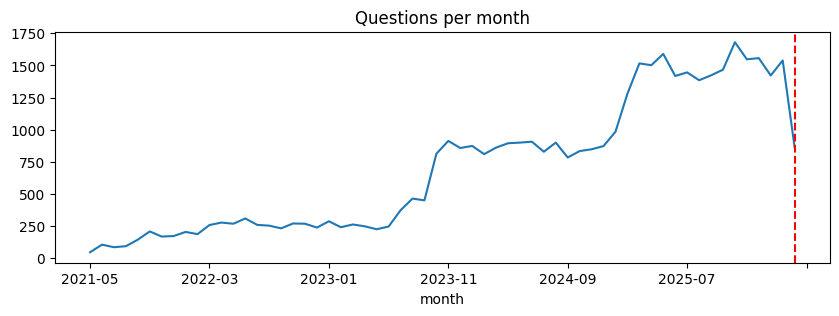

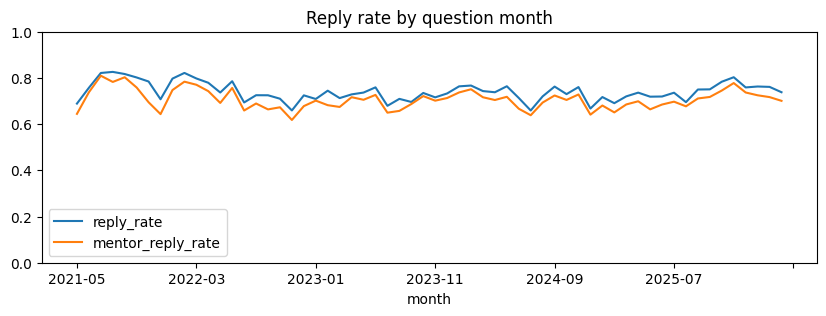

In [24]:
m = q.assign(month=pd.to_datetime(q.q_ts, utc=True).dt.strftime("%Y-%m")).groupby("month").agg(
    questions=("question_revid", "size"), reply_rate=("has_any_reply", "mean"), mentor_reply_rate=("has_mentor_reply", "mean"))
display(m.tail(8))
ax = m.questions.plot(figsize=(10, 3), title="Questions per month"); ax.axvline(len(m) - 1, color="red", ls="--")
m[["reply_rate", "mentor_reply_rate"]].plot(figsize=(10, 3), title="Reply rate by question month", ylim=(0, 1))
lag = (pd.to_datetime(q.first_reply_ts, utc=True) - qts).dt.total_seconds() / 3600
print("hours from question to first reply:\n" + lag.describe(percentiles=[.25, .5, .75, .9]).round(2).to_string())
print("\nturns per thread:\n" + q[found].n_turns.value_counts().sort_index().head(12).to_string())

**What the output shows.** The last months have about 1,400 to 1,700 questions each, with reply rates of 74% to 80%. April 2026
has only 863 questions because the data stop on 20 April. Its reply rate (73.8%) is close to earlier months, although its newest
questions had little time to get an answer. Half of the first replies arrive within 5.5 hours, and 90% within about 3 days. The
smallest value, -0.01 hours, is not a reply before the question: reply times are known only to the minute, so a reply in the same
minute can look a few seconds early. Most threads have 2 turns (question and one reply); 18 found threads have 0 turns (no signed
comment could be read; all 18 are also flagged `turn_source_mismatch` and 10 were deleted at once).

## 8. Summary (written to results/m2_report.json, read by M9)

**What this does.** Writes the key counts to a small file that the final report reads, and prints the overall check tally.

In [25]:
report = {"n_questions": len(q), "n_topup": int((q.source == "topup").sum()),
          "thread_found_rate": round(float(q.thread_page.notna().mean()), 4),
          "reply_rate": round(float(q.has_any_reply.mean()), 4),
          "mentor_reply_rate": round(float(q.has_mentor_reply.mean()), 4),
          "n_away_routed": int(q.away_routed.sum()), "n_editing_page": int(q.editing_page.sum()),
          "first_replier_role": q.first_replier_role.value_counts().to_dict(),
          "flags": {k: int(v) for k, v in flags.items()}}
(config.RESULTS / "m2_report.json").write_text(json.dumps(report, indent=1))
print(json.dumps(report, indent=1))
print(f"\nchecks passed: {sum(ok for _, ok in ck.items)} / {len(ck.items)}; "
      f"tracer and random questions fully matching: {sum(tracer_ok) + sum(rand_ok)} / {len(tracer_ok) + len(rand_ok)}")

{
 "n_questions": 42316,
 "n_topup": 8,
 "thread_found_rate": 0.9977,
 "reply_rate": 0.7379,
 "mentor_reply_rate": 0.7045,
 "n_away_routed": 517,
 "n_editing_page": 7791,
 "first_replier_role": {
  "page_mentor": 29289,
  "third_party": 1207,
  "other_mentor": 657
 },
 "flags": {
  "turn_source_mismatch": 3322,
  "section_removed_immediately": 1078,
  "thread_not_found": 96,
  "page_owner_differs": 66,
  "unrecoverable_revdel": 61,
  "first_turn_not_mentee": 44,
  "turn_after_cutoff_dropped": 43,
  "reply_before_question": 22,
  "question_turn_relabelled": 11,
  "question_merged_into_reply": 4,
  "turn_source_regex": 1
 }
}

checks passed: 58 / 58; tracer and random questions fully matching: 65 / 65


**What the output shows.** In the run on the final data (cutoff 2026-04-20T14:00Z): 42,316 questions (8 from the top-up), a thread found for 99.77%, any reply for
73.8% and a mentor reply for 70.5% (both rates are out of the 42,220 questions with a thread; the 96 without one have no reply value).
517 questions went to a backup mentor and 7,791 were asked while editing. All 58 automatic checks passed, and all 65 tracer
and random questions shown matched on every field. The one item worth a reviewer's note is the 25 replies by a mentor's new
account labelled third party (section 6), which affects only the mentor-reply robustness measure.